(ai-assisted-programming)=
# AI-assisted programming in biology

[ADD ILO'S AND PREREQUISITES LIKE OTHER CHAPTERS]

[CONVERT THE FOLLOWING PARA TO PREREQUISITES]

<!-- You need Python functions and CSV basics, elementary R, and enough Bash to run a script. Review [Python](python.ipynb), [R](r.ipynb) or [Unix](unix.ipynb) as needed. Run this notebook with a Python 3 kernel and Jupyter support, plus Bash, `awk` and base R with `Rscript`. The [VS Code notebook guide](../appendices/vscode.md#jupyter-notebooks-choose-a-kernel-deliberately) explains kernel selection; [Copilot setup](../appendices/vscode-copilot.md) covers accounts and sign-in. -->

[CONVERT THE FOLLOWING PARA TO "HOW TO NAVIGATE THIS CHAPTER"; MAKE THE SECTION REFERENCES TOPICAL, USING TAGS, NOT HARD-CODED NUMBERS THAT MIGHT CHANGE AS THE CHAPTER UNDERGOES REVISIONS OVER TIME; MAKE THE REFERENCE TO THE ACCOMPANYING LECTURE STUDENT FACING ASSUMING IT HAS BEEN FINALISED]

<!-- Read sections 1–6, then choose from the practicals in section 7. Start with a short task at each Bloom level and one capstone; return to the other examples later. Set aside another 60–90 minutes for the integration project, P1. The [accompanying lecture](../lectures/ai_coding/ai_coding.html) is in progress . -->

Generative AI is changing how we solve problems across disciplines. This chapter covers ... - how to turn ideas or problems into a solution that is working software. 

Coding tools now range from suggestions for a single line of code to agents that can inspect a project, plan a change, edit several files and run tests. They combine models that generate responses with tools that act on code and use the results to guide further work. See the [VS Code AI workflow overview](https://code.visualstudio.com/docs/agents/overview) for examples. 

For a biologist, AI offers the opportunity is to spend less effort wrestling with unfamiliar syntax and more on designing and investigating an analysis. Current AI agents can produce a page of code before you have finished deciding what to call the file! *But you need to be sure that it answers the (biological) question correctly, and that your brain is not turning to mush in the process!*

The technology is changing quickly. Models, interfaces and the kinds of work we can delegate keep being revised; the VS Code-Copilot [release notes](https://code.visualstudio.com/updates) give a flavour of the pace. Learning today's collection of model names and buttons will only take us so far. We need ways of thinking and working that remain useful as the tools change.

**What must remain constant is the need for human judgement.** We still have to frame useful biological questions, choose assumptions and methods, weigh evidence and decide whether a conclusion follows. These involve the higher-level skills of **analysing, evaluating and creating** in [Bloom's taxonomy](#ai-bloom), which we will explore later. AI can support these activities too. Using it well means exercising those skills: understanding the choices, checking the evidence and taking responsibility for the resulting analysis. That is what we will learn amd practise in this chapter.

**Our overararching approach will remain the same: plan → implement → test → explain → rerun.**

[WHAT IS THE FOLLOWING SENTENCE FOR?]
<!-- **Draft for human review.** Work with a live assistant or use the prepared suggestions in this notebook. Both routes use the same predictions and checks, and the notebook runs locally without an AI account.  --> 

[REMOVE HARD-CODED SECTION NUMBERS - SEE OTHER BOOK CHAPTERS AND README FOR CONVENTIONS REGARDING THIS]

[INSERT A SUCCINCT, INTUITIVE PRIMER FOR NOVICE/STARTING PROGRAMMERS IN THE FORM OF A SECTION ON "HOW GENERATIVE AI FOR PROGRAMMING WORKS"; IT SHOULD INCLUDE A BRIEF EXPLANATION OF WHAT AI AND GENAI IS IN GENERAL].

[THE FOLLOWING EXAMPLE NEEDS REVISION AND POTENTIALLY, RELOCATION; CONTEXT AT THE START IS UNCLEAR; ITS TITLE SHOULD BE MORE DIRECT; WHAT "COUNTS" MEANS IS UNCLEAR; THE SUBSEQUENT CODE CELL AND ITS EXPLANATION ARE ALMOST ENTIRELY UNUNDERSTANDABLE]

(ai-plausible)=
## 1. Why a plausible answer needs checking

A field team records counts at several sites. An empty count means *not recorded*, not *we looked and found none*. At site C both visits have missing counts. What should its known total be: zero, or unavailable?

Write down your prediction before running the next cell. The candidate is short, readable and wrong. It has all the confidence of someone who did not attend the field trip.

[REPLACE UNNECESSARILY TECHNICAL TERMS LIKE "FIXTURE" WITH MORE HUMAN TERMS]

[DON'T HARD-CODE REFERENCES TO SECTIONS OR EXAMPLES, OR PROVIDE THEM WITHOUT CONTEXT; FOR EXAMPLE, "We will test them in E1"]

The example follows MQB's [observations exercise](python.ipynb) and its [boundary fixture](../data/bootcamp_observations_boundary.csv). Sum known non-negative integer counts, count missing observations separately, and count each exact duplicate record only once. If there are no known counts, return `None`. These rules are our **specification**, or **contract**: what the program must do. We will test them in E1.

In [2]:
import csv
import io

boundary_rows = list(csv.DictReader(io.StringIO(
    "site,date,count\n"
    "C,2026-10-01,\nC,2026-10-02,\n"
    "D,2026-10-01,0\nD,2026-10-01,0\n"
)))
candidate_total_C = sum(int(row["count"] or 0)
                        for row in boundary_rows if row["site"] == "C")
expected_C = (None, 2)  # unavailable known total; two missing observations
assert candidate_total_C == 0
assert candidate_total_C != expected_C[0]
print("Candidate total for C:", candidate_total_C)
print("Expected (known_total, missing_count):", expected_C)


Candidate total for C: 0
Expected (known_total, missing_count): (None, 2)


The candidate changed “we do not know” into “there were none”. A later comparison of sites would now contain invented evidence of absence.

Python executed the code, but the result misrepresented the field observations. Ask three questions whenever you receive a suggestion: **what question does this answer, what assumptions does it make, and what check would catch a wrong answer?**

For site D, zero *is* correct: there is an observed zero, repeated in an exact duplicate row. C and D must not become indistinguishable. Our tests need to preserve that distinction.


(ai-how-it-works)=
## 2. How an AI coding assistant works

Imagine extending a partly written recipe. From examples, you have learned that a list of ingredients is often followed by preparation steps, and that “bake” usually involves something more specific than waving a cake tin hopefully at the oven.

A generative model learns patterns from large collections of text and code. When you use it, the tool supplies your request and context: perhaps a selected function, nearby code, a file search or a test result. The model then generates a response piece by piece. These pieces, called **tokens**, can be parts of words, punctuation or code.

Those learned patterns can produce useful explanations and programs. They can also produce a plausible function that doesn't exist, convert the wrong units, or turn a missing observation into a zero. The early [code-generation study by Chen and colleagues](https://arxiv.org/abs/2107.03374) tested whether generated programs worked correctly. We need to ask the same question.

### Training, context and tools are different things

**Training** is how the model acquired its patterns. **Context** is the information supplied for your current task. Attaching a file gives the model context; it doesn't retrain it.

Tools can retrieve current documentation or inspect a repository and add what they find to the context. Check which files the assistant actually read: mentioning a filename doesn't give it the file's contents.

An **agent** can use tools to read files, edit code and run commands. It can repeat these steps to investigate a failing test. Review both the code changes and any changes to the tests: rewriting a test to accept a mistake is an elaborate way of avoiding the question.

The same request can produce different responses. A precise request helps define the task, but the result still needs checking. Compare the next two expressions: both work on the easy example. Which boundary case separates them?


In [2]:
suggestions = {
    "strict": lambda values: sum(value > 10 for value in values),
    "inclusive": lambda values: sum(value >= 10 for value in values),
}
assert all(function([8, 12]) == 1 for function in suggestions.values())
boundary_results = {name: function([10]) for name, function in suggestions.items()}
assert boundary_results == {"strict": 0, "inclusive": 1}
print("Same easy case; different boundary behaviour:", boundary_results)


Same easy case; different boundary behaviour: {'strict': 0, 'inclusive': 1}


(ai-bloom)=
## 3. Human reasoning, Bloom's taxonomy and algorithms

Why learn to code if an assistant can write it? Because choosing the question, specifying a method and deciding whether a result means anything are not typing tasks.

Bloom's revised taxonomy gives names to six kinds of thinking. Here is our application to computational biology, using [Krathwohl's overview of the revision](https://doi.org/10.1207/s15430421tip4104_2). Start with **Create** when planning an analysis; practise the smaller skills from **Remember** upwards.

| Kind of thinking | What you do | Examples in this chapter |
| --- | --- | --- |
| Create | Define a new workflow and the evidence it must produce. | [C-A](#ai-ca), [C-B](#ai-cb), [C-C](#ai-cc), [P1](#ai-p1) |
| Evaluate | Accept, revise or reject a candidate against a specification. | [E1–E4](#ai-evaluate) |
| Analyse | Trace a failure or measure a bottleneck. | [N1](#ai-n1), [N2](#ai-n2) |
| Apply | Use a known calculation in another language or context. | [A1–A3](#ai-apply) |
| Understand | Explain behaviour and its assumptions in your own words. | [U1–U3](#ai-understand) |
| Remember | Recall syntax for an operation you already understand. | [R1–R4](#ai-remember) |

Bloom's levels describe your thinking, not the assistant's buttons. Chat can help you design an analysis; an agent can make a one-line edit. The consequences of the change determine how carefully you need to check it. A one-character comparison can alter a biological result, as our plant heights will demonstrate.

The [MQB AI Assessor project](https://github.com/MulQuaBio/MQB_AI_Assessor) connects this approach to assessment design. Here, predictions, tests, design decisions and explanations provide evidence of understanding. The amount of generated code tells us much less.

### The connection to algorithms

Before asking for implementation, name the inputs, outputs, assumptions and ordered steps. That is already algorithmic thinking. When comparing alternatives, ask about correctness first, then time and memory. A faster wrong summary is not an improved analysis; it is merely wrong with excellent time management.

See the draft [algorithms chapter](https://github.com/MulQuaBio/MQB/blob/docs/algorithms-problem-solving-review/content/notebooks/algorithms.md), [algorithms lecture](https://github.com/MulQuaBio/MQB/blob/docs/algorithms-problem-solving-review/content/lectures/algorithms/algorithms.qmd) and [development discussion](https://github.com/MulQuaBio/MQB/issues/220) for more on specifying and comparing algorithms.


(ai-interfaces)=
## 4. Choosing an interaction and an interface

Ask for the smallest useful piece of help. If you need to understand a condition, start with that condition, not “please refactor my entire scientific life”.

(ai-copilot-options)=
### Chat is the interface; Ask, Plan and Agent are modes

**Chat** is where you have the conversation. The **mode** determines the kind of help and tools available; the **model** generates the response. Permissions control which actions can run. Changing the model doesn't change those permissions.

For Copilot in VS Code, the [built-in agents guide](https://code.visualstudio.com/docs/agents/run/agent-harnesses#choose-a-built-in-agent) distinguishes:

| Mode | What it does | Useful MQB request |
| --- | --- | --- |
| Ask | Explains and investigates without editing files; Copilot's Ask uses read-only tools. | “Why does this observations summary turn missing counts into zero?” |
| Plan | Investigates a task and proposes an implementation plan for review. | “Plan the location-level rejection summary. State the denominator and tie rules.” |
| Agent | Implements changes and uses tools to check the result, within its permissions. | “Connect the checked producer, R figure and Bash runner in P1. Stay within the agreed files.” |

Use the mode/agent picker to choose; Copilot also offers planning through `/plan`. The available controls depend on your version and organisation. Use the {ref}`appendix controls check <copilot-controls>` to find them.

### Completions and focused edits

An **inline completion** is suggested code appearing as you type. State the intended operation, read the suggestion and predict a boundary case before accepting it.

**Inline chat** lets you make a request beside your code. Use it for a focused edit, such as adding A3's documentation. Review the diff and rerun the checks. **Quick Chat** is a small panel for a short conversation. See the [inline and Quick Chat guide](https://code.visualstudio.com/docs/chat/inline-chat).

A **diff** shows the lines removed and added. In A3, check that only documentation changed. In P1, check how the changes across several files fit together and whether the calculations still follow the agreed specification.

Older tutorials use a separate **Edit mode**: you selected files and reviewed proposed edits. VS Code has deprecated this mode in favour of Agent or a custom agent, though some managed installations still show it. Check the [Edit-mode change](https://code.visualstudio.com/updates/v1_126#_edit-mode) if a tutorial's buttons differ from yours.

(ai-model-choice)=
### How should you choose a model?

Start with **Auto and the default thinking effort**. Our aim is to answer a biological question, not acquire a second degree in model names.

1. **Check the service and account first.** Use an approved account and shareable practice data. Model choice does not settle the [data-use questions](#ai-data).
2. **Let Auto handle ordinary choices.** It routes requests using task complexity and availability. Where its priority menu is offered, Efficiency favours lower credit use, Balance is the middle option, and Intelligence favours capability for harder work. For MQB, start with Balance or the managed default. See [Auto and model controls](https://code.visualstudio.com/docs/agent-customization/language-models).
3. **Choose manually only when it helps.** If your account permits it, use a fast model for syntax, short explanations and routine edits; consider a reasoning model for a difficult diagnosis or multi-step design. This follows the [task-based model guidance](https://code.visualstudio.com/docs/agents/concepts/language-models#choose-the-right-model). First make the question and relevant context clear: changing models will not repair an unspecified denominator.
4. **Compare results against your checks.** If a suggestion fails, identify the failure, clarify the request and, where useful, try another model. Use the same inputs and expected results. Two agreeable models are not a peer-review panel.
5. **Record what you actually used.** Note the tool, date, selected model or Auto, useful suggestion and verification. Auto can choose different models; inspect the response details where available rather than inventing a model name.

**Access, checked 23 October 2026:** GitHub lists Copilot Free and Student as Auto-only plans. Institutional Business access offers different choices, subject to organisation policy. See the [current plan comparison](https://docs.github.com/en/copilot/get-started/plans) for your account's options.

(ai-model-settings)=
### What do the other settings change?

- **Thinking effort** controls how much reasoning a supported model attempts. Start with the default; higher settings can increase waiting time and credit use. Check the result with the same tests.
- **The chat model and completion model have separate settings.** See [model configuration](https://code.visualstudio.com/docs/agent-customization/language-models#configure-models-for-other-features) for chat, inline chat and completions. Start with their defaults.
- **Context** includes your selected code, attached files, conversation and retrieved material. A larger context window holds more information. Choose what the task needs and inspect it before sending.
- **Permissions** control what the assistant can do. Use Manual permissions and inspect the existing automatic-approval rules: pre-approved actions can still run without a new confirmation. Review commands and diffs. Allow all skips confirmations; sandboxing is a separate control. See [approvals and permissions](https://code.visualstudio.com/docs/agents/run/approvals).

Check your remaining allowance before a long session. Context, generated output, reasoning and tool activity can affect usage. See the [model concepts guide](https://code.visualstudio.com/docs/agents/concepts/language-models#ai-credits-and-model-costs) and the linked plan documentation for current allowances.

### Work through a choice before clicking

| Your immediate need | A sensible starting choice | Evidence you still need |
| --- | --- | --- |
| Explain why a height of exactly 10 cm was counted. | Ask with Auto; supply the condition and your prediction. | Hand-check the list and the equality case. |
| Add units and errors to a tree-height docstring. | Explain the contract first, then request a focused inline edit or bounded Agent edit. Auto is sufficient as a starting choice. | A documentation-only diff and unchanged results in A3. |
| Build P1's multi-file analysis. | Review a Plan, then use Agent with Manual permissions. For a difficult design, consider Auto's Intelligence priority or an available reasoning model. | Protected inputs, hand-worked results, failure checks and your own rerun. |

Before moving on, explain: **if you keep the model but switch from Ask to Agent, what changes? If you choose a stronger model, do you still need the same boundary tests?** Answer without consulting the assistant.

### VS Code versus Copilot on GitHub.com

In VS Code, you work beside local files, uncommitted edits, your terminal and debugger. On GitHub.com, the useful starting context is hosted repository content, issues and pull requests. Cloud agents can work and test in a remote development environment; that is not your laptop's current Python environment.

| Question | VS Code | GitHub.com |
| --- | --- | --- |
| Which files? | Local project context supplied by the editor/tools. | Hosted repository and conversation context available to that feature. |
| Which changes? | Local edits you inspect in the editor. | Hosted changes you inspect through the repository/PR workflow. |
| Where are commands run? | Check the selected local or remote environment. | A cloud task uses its configured remote environment. |
| When is it useful? | Immediate editing, debugging and checking your analysis. | Repository questions, reviews and delegated hosted work. |

GitHub.com won't see your uncommitted local edits, and a successful cloud run doesn't check your laptop's dependencies. Choose the environment in which you need the work done. The [VS Code workflow guide](https://code.visualstudio.com/docs/agents/overview) and [Copilot on GitHub.com guide](https://docs.github.com/en/copilot/concepts/copilot-surfaces/copilot-on-github) describe the available features.


(ai-data)=
## 5. Where your code and data go

When you run Python locally, the calculation happens on your computer. When you ask a remote assistant for help, your request leaves it. Decide what you are willing and allowed to send before making the request.

A request can contain your message, selected code, attached files, other project context and tool output. Selecting four lines is not proof that those are the only four lines the tool will send. Inspect the listed context and the tool's documentation.

For a Copilot request using an OpenAI model, the useful picture is:

```text
your editor: message + supplied context
          → GitHub Copilot service
          → the model host used for that feature
          ← generated response
          ← suggestion shown in the editor
```

GitHub documents OpenAI models hosted by OpenAI and GitHub's Azure infrastructure, along with a downstream zero-data-retention agreement with OpenAI. Check GitHub's own retention rules separately: the model host's agreement doesn't cover every record held by the service. See [model hosting](https://docs.github.com/en/copilot/reference/ai-models/model-hosting) and GitHub's [privacy statement](https://docs.github.com/en/site-policy/privacy-policies/github-general-privacy-statement).

### Processing, retention and training

**Processing** produces the answer. **Retention** means keeping information afterwards, for example in chat history, application state or security logs. **Training** uses information to improve a later model. A service may also allow authorised staff to review information for security or support.

Turning off training still allows the service to process the request. Deleting a visible chat may leave other service records subject to their own retention rules. Check each separately.

### How accounts and services differ

Sources for this comparison were checked on **22 October 2026**. Use the row for your service and account: an education email address alone doesn't establish which licence or policy applies.

| Route | What is sent and the training rule | Storage and controls |
| --- | --- | --- |
| Personal GitHub Copilot | Supplied context goes through GitHub and the selected hosting route. GitHub documents model-training use for specified individual plans and an opt-out. | Inspect the available Copilot settings; managed policies may override personal choices. GitHub's retention rules and the model host's commitments are separate. |
| Copilot Business/Enterprise | GitHub documents no model training on these customers' data without authorisation. | Organisation/enterprise administrators control managed policies. Check the agreement and feature for processing and retention conditions. |
| Personal ChatGPT | Requests and attachments go to ChatGPT. Check the account's Data controls. **Draft check: verify current personal-account training and retention defaults.** | Check the policy for your plan and feature before sending research material; API and enterprise commitments apply to different accounts. |
| Institution-managed ChatGPT Work | OpenAI documents no training by default on Business, Enterprise and Edu workspace data. | Conversations, execution state and connected systems have distinct retention arrangements. Administrators manage workspace controls; API zero-data-retention controls do not define Work retention. |
| Direct OpenAI API | OpenAI documents no training on API data unless the customer opts in. | Default abuse-monitoring logs can be retained for up to 30 days, with stated exceptions; feature-specific application storage is separate. Modified/zero-retention controls require eligibility and approval. |

Sources: [Copilot policies](https://docs.github.com/en/copilot/how-tos/manage-your-account/manage-policies), [GitHub privacy](https://docs.github.com/en/site-policy/privacy-policies/github-general-privacy-statement), [ChatGPT data-settings pointer](https://learn.chatgpt.com/docs/browser), [managed Work security](https://learn.chatgpt.com/docs/enterprise/chatgpt-work-cloud-security), and [OpenAI API data controls](https://developers.openai.com/api/docs/guides/your-data).

### A control you can inspect

GitHub documents **Copilot settings → Allow GitHub to use my data for AI model training → Disabled** for eligible individual plans. Check your plan first; Business/Enterprise licences don't show this control.

You can choose whether to use a remote service, limit what you send, and inspect the available training, history, deletion and connected-tool settings. For a managed account, check which controls belong to your administrators and which conditions are fixed by the provider's agreement. A prompt saying “keep this private” is not a data-processing agreement.

### A fieldwork decision

Suppose an ecologist wants help with a script containing sensitive survey coordinates. What needs to leave the computer? Try explaining the calculation with made-up coordinates and species labels. Check filenames and tracebacks too: removing coordinates from one table won't help if they appear elsewhere in the request.

Before running the next cell, predict which fields you would remove from the request. The cell builds a **fictional context preview** locally; it sends nothing to an assistant.


In [ ]:
fictional_record = {"location": "sensitive survey location",
                    "latitude": "RESTRICTED", "count": 4}
shareable_example = {"location": "made-up site A", "count": 4}
context_preview = {
    "message": "Explain why an empty count must not become an observed zero.",
    "attached_example": shareable_example,
    "other_files": [],
}
assert "latitude" not in shareable_example
assert "RESTRICTED" not in repr(context_preview)
assert fictional_record["latitude"] == "RESTRICTED"  # source remains unchanged
print(context_preview)

{'message': 'Explain why an empty count must not become an observed zero.', 'attached_example': {'location': 'made-up site A', 'count': 4}, 'other_files': []}


Before sending a real request, answer: **what will I send, what may the service do with it, and am I allowed to share it?** A private repository, an opt-out and institutional access do not answer all three.

Now explain without looking back: *if training is disabled, does the request stay on my computer, and does the provider keep no record?* Name the processing and retention rules you would still need to check.


(ai-request)=
## 6. Asking for help responsibly

A useful request states **goal → attempt → help → check**. Here is one for our observations example:

> My biological question is the known total and number of missing observations at each site. An empty count is missing, not zero; exact repeated records count once. My current expression uses `int(count or 0)`, so an all-missing site becomes zero. Explain that error and suggest a small change to the summary function only. I will check site C gives `(None, 2)`, site D gives `(0, 0)`, invalid counts raise an error, and the input rows are unchanged. Do not install packages or edit my data.

A prepared response might say: “Track whether any known count was observed; return `None` when none was seen.” That is a useful proposal. A response saying “just remove the empty rows” loses the missing-observation count and should be rejected. The specification, not the persuasiveness of the paragraph, decides.

### Predictable failure patterns

Invented functions need a documentation check. Unit conversions need a hand calculation. Missing data need an explicit rule. A proposed “environment fix” needs a fresh-process rerun with recorded dependencies. E1–E3 turn each of these into a small, testable problem.

Use the same standard for human- and AI-authored suggestions. E4 asks you to judge two candidates before revealing their provenance. A person can make a fluent mistake too; we have an excellent historical record of this.

### Permission and acknowledgement

For coursework, follow the assignment brief's rules on assistance and acknowledgement. For research, check the project's data-sharing, authorship and collaboration requirements.

For a permitted use, your acknowledgement might look like this:

> Tool: GitHub Copilot; date: 22 October 2026; purpose: explanation of a missing-value bug. I used the distinction between an unobserved total and an observed zero, wrote the change myself, and checked ordinary, all-missing, duplicate and invalid records against hand-worked expectations.

Record the tool, date and contribution accurately. If you used a prepared candidate, describe what you reviewed and tested.

For larger edits, agree on a plan, the files to change and the commands to run. Get human approval before expanding that scope, installing dependencies, accessing the network or publishing through Git. Check the tool's permissions as well as the instructions in your prompt. P1 puts these review checkpoints into practice.


(ai-practicals)=
## 7. Practicals across Bloom's taxonomy

The practicals revisit familiar MQB problems. Each gives a question, preparation, a suggested request, runnable code and checks. Use a live assistant or review the prepared candidate; both routes require you to **predict or design first, then inspect and test the suggestion**.

For a short route, try R2, U1, the function part of A1, N1, E1/E4, and one of C-A/C-B/C-C. Explore the other examples afterwards, or tackle P1 as a separate integration project. Activity IDs let you find the tasks selected for a workshop.

### Prepare a practice workspace

Download the [input pack](../data/workshop_ai_inputs.zip) before working offline. It contains copies of MQB's observations fixtures, tree table, Blackbirds text, E. coli FASTA and observations reference implementation. The next cell finds it in an MQB checkout. If you downloaded only this notebook, put the pack beside it.

The setup cell creates a new temporary project and prints its location. Each file-writing cell names the file it changes. Keep your own attempts in separate `my_` files: rerunning a supplied candidate cell replaces its files. The final cell saves the practice project as an archive.

The notebook runs commands from this new project's root folder. To work outside the notebook, open the printed folder in VS Code and use its `code/`, `data/` and `results/` paths. Python uses the current kernel's interpreter; R and Bash run as separate processes.


In [4]:
from pathlib import Path
import copy
import csv
import hashlib
import importlib.util
import io
import json
import math
import os
import shutil
import subprocess
import sys
import tempfile
import textwrap
import zipfile

PYTHON = sys.executable
for executable in ("bash", "awk", "Rscript"):
    if shutil.which(executable) is None:
        raise RuntimeError(f"Install/enable {executable} using the MQB setup guide before running.")
pack_candidates = [
    Path.cwd() / "data" / "workshop_ai_inputs.zip",
    Path.cwd() / "workshop_ai_inputs.zip",
    Path.cwd().parent / "data" / "workshop_ai_inputs.zip",
    Path.cwd() / "content" / "data" / "workshop_ai_inputs.zip",
]
PACK = next((path for path in pack_candidates if path.is_file()), None)
if PACK is None:
    raise FileNotFoundError("Put workshop_ai_inputs.zip beside the notebook, or use the MQB checkout.")

WORKSPACE = Path(tempfile.mkdtemp(prefix="mqb-ai-coding-"))
for folder in ("code", "data", "results", "sandbox"):
    (WORKSPACE / folder).mkdir()

def write_practice(relative, source):
    destination = WORKSPACE / relative
    if not destination.resolve().is_relative_to(WORKSPACE.resolve()):
        raise ValueError("Practice files must stay inside the new workspace.")
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(textwrap.dedent(source).lstrip("\n"), encoding="utf-8")
    return destination

def run(command, *, ok=True, show=True, env=None):
    settings = os.environ.copy()
    settings["MQB_PYTHON"] = PYTHON
    if env:
        settings.update(env)
    result = subprocess.run([str(item) for item in command], cwd=WORKSPACE,
                            env=settings, capture_output=True, text=True, timeout=45)
    if ok and result.returncode != 0:
        raise AssertionError(f"{command!r} failed:\n{result.stdout}\n{result.stderr}")
    if not ok and result.returncode == 0:
        raise AssertionError("Expected this deliberately faulty command to fail.")
    if show:
        message = (result.stdout + result.stderr).strip()
        print(message[:3000] if message else f"exit status: {result.returncode}")
    return result

def load_practice(relative, name):
    specification = importlib.util.spec_from_file_location(name, WORKSPACE / relative)
    module = importlib.util.module_from_spec(specification)
    specification.loader.exec_module(module)
    return module

def read_csv(relative):
    with (WORKSPACE / relative).open(newline="", encoding="utf-8") as stream:
        return list(csv.DictReader(stream))

def expect_error(exception, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except exception:
        return
    raise AssertionError(f"Expected {exception.__name__}")

with zipfile.ZipFile(PACK) as archive:
    (WORKSPACE / "LICENSE").write_bytes(archive.read("LICENSE"))
    names = ["e_coli.fasta", "bootcamp_observations.csv",
             "bootcamp_observations_boundary.csv", "bootcamp_observations_invalid.csv",
             "trees.csv", "blackbirds.txt",
             "workshop_ricker_traces.csv", "workshop_lv_traces.csv"]
    for name in names:
        (WORKSPACE / "data" / name).write_bytes(archive.read(name))
    (WORKSPACE / "code" / "workshop_observations_reference.py").write_bytes(
        archive.read("observations_exercise_solution.py"))
SOURCE_HASHES = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in (WORKSPACE / "data").iterdir() if p.is_file()}
write_practice("README.md", "# AI-assisted coding practice\n\nRun commands from this project root.\n")
reference = load_practice("code/workshop_observations_reference.py", "workshop_reference")
ordinary = read_csv("data/bootcamp_observations.csv")
boundary = read_csv("data/bootcamp_observations_boundary.csv")
invalid = read_csv("data/bootcamp_observations_invalid.csv")
print("Practice project:", WORKSPACE)
print("Python:", sys.version.split()[0])
print("Bash, awk and base R are available; no AI request has been sent.")


Practice project: /tmp/mqb-ai-coding-cziyqc3b
Python: 3.14.4
Bash, awk and base R are available; no AI request has been sent.


(ai-remember)=
### Remember

The useful question here is “I know what operation I want; what is the syntax?” If you do not yet know what the operation should mean, autocomplete has arrived slightly early to the meeting.


(ai-r1)=
#### R1 — Read a file and select oaks

**Remember · 10–15 minutes · preparation:** Python lists, file reading and CSV headers. Source: [Python foundations](python.ipynb).

Our small table has a header and three species. Read the rows as dictionaries, read a text note with `with open(...)`, then select species whose genus is exactly `Quercus`. Predict the two selected species first. A string containing “Quercus” somewhere is not the same rule.

**Try asking:** “Complete only the CSV reader and the list comprehension. Use the named columns; do not infer a different schema.”

Start with the next cell's supplied list and write your own filter. Then read the prepared candidate's expression aloud and compare its results with your prediction. Explain what `DictReader` does with the first line and why the file closes after the `with` block.


In [5]:
write_practice("data/workshop_species.csv",
               "species,height_cm\nQuercus robur,8\nPinus sylvestris,12\nQuercus ilex,15\n")
write_practice("data/workshop_note.txt", "An empty count is not an observed zero.\n")
species_for_attempt = ["Quercus robur", "Pinus sylvestris", "Quercus ilex"]
my_oaks = [name for name in species_for_attempt if name.split()[0] == "Quercus"]
assert my_oaks == ["Quercus robur", "Quercus ilex"]
print("My independently predicted selection:", my_oaks)


My independently predicted selection: ['Quercus robur', 'Quercus ilex']


In [6]:
with (WORKSPACE / "data/workshop_species.csv").open(newline="", encoding="utf-8") as stream:
    species_rows = list(csv.DictReader(stream))
with (WORKSPACE / "data/workshop_note.txt").open(encoding="utf-8") as stream:
    note = stream.read().strip()
candidate_oaks = [row["species"] for row in species_rows
                  if row["species"].split()[0] == "Quercus"]
assert candidate_oaks == ["Quercus robur", "Quercus ilex"]
assert species_rows[0]["height_cm"] == "8"  # CSV text has not become a number by magic
assert note == "An empty count is not an observed zero."
print(candidate_oaks)
print(note)


['Quercus robur', 'Quercus ilex']
An empty count is not an observed zero.


(ai-r2)=
#### R2 — A one-character botanical disagreement

**Remember · 10 minutes · preparation:** R vectors and matrices. Source: [R basics](r.ipynb).

For heights 8, 12, 10 and 15 cm, count values **strictly greater** than 10. Predict the result, then the result for `c(10)` and `numeric(0)`. Also predict row means for the two rows `1, 3, 5` and `2, 4, 6`.

**Try asking:** “Suggest the R expressions for the strict count and matrix row means. Leave my data unchanged.” The candidate uses `c()`, `sum()` and `apply()`. The Python cell writes the practice script and runs it in R; Python is supervising, not translating R by interpretive dance.

Check all five expectations. Explain why `apply(x, 1, mean)` means rows, and why replacing `>` with `>=` changes the scientific question.


In [7]:
r_recall = write_practice("code/workshop_recall.R", r'''
heights_cm <- c(8, 12, 10, 15)
count <- sum(heights_cm > 10)
measurements <- matrix(c(1, 3, 5, 2, 4, 6), nrow=2, byrow=TRUE)
row_means <- apply(measurements, 1, mean)
stopifnot(count == 2, sum(c(10) > 10) == 0, sum(numeric(0) > 10) == 0)
stopifnot(identical(as.numeric(row_means), c(3, 4)))
print(list(strict_count=count, row_means=row_means))
''')
run(["Rscript", "code/workshop_recall.R"])


$strict_count
[1] 2

$row_means
[1] 3 4


CompletedProcess(args=['Rscript', 'code/workshop_recall.R'], returncode=0, stdout='$strict_count\n[1] 2\n\n$row_means\n[1] 3 4\n\n', stderr='')

(ai-r3)=
#### R3 — Flags with consequences

**Remember · 10–15 minutes · preparation:** Shell paths and text matching. Source: [Unix](unix.ipynb).

Predict which lines `grep -i -w -n oak` selects: `oak`, `OAK`, `soak`, or `an oak tree`? Then predict which text files lie no more than two levels below a search root.

**Try asking:** “Recall those flags and explain each one; do not broaden the search.” The candidate creates a small practice directory, including a filename with spaces.

Run the checks and inspect the line numbers. Use `grep --help` or the local manual to check `-i`, `-w` and `-n`. The depth test uses Python to count directory levels. Where GNU `find -maxdepth` is available, it compares both methods; on BSD/macOS, use the Python test. Why must you quote a shell wildcard passed to `find`?


In [8]:
write_practice("sandbox/workshop_flags/records.txt", "oak\nOAK\nsoak\nan oak tree\n")
write_practice("sandbox/workshop_flags/one space.txt", "x\n")
write_practice("sandbox/workshop_flags/sub/visible.txt", "x\n")
write_practice("sandbox/workshop_flags/sub/deeper/hidden.txt", "x\n")
matched = run(["grep", "-i", "-w", "-n", "oak", "sandbox/workshop_flags/records.txt"])
assert matched.stdout.splitlines() == ["1:oak", "2:OAK", "4:an oak tree"]
search_root = WORKSPACE / "sandbox/workshop_flags"
portable = sorted("./" + path.relative_to(search_root).as_posix()
                  for path in search_root.rglob("*.txt")
                  if len(path.relative_to(search_root).parts) <= 2)
find_probe = subprocess.run(["find", ".", "-maxdepth", "2", "-name", "*.txt"],
                            cwd=search_root, capture_output=True, text=True)
if find_probe.returncode == 0:
    assert sorted(find_probe.stdout.splitlines()) == portable
else:
    print("This find lacks -maxdepth; using the checked Python depth rule.")
assert portable == ["./one space.txt", "./records.txt", "./sub/visible.txt"]
print("Files at depth <= 2:", portable)


1:oak
2:OAK
4:an oak tree
Files at depth <= 2: ['./one space.txt', './records.txt', './sub/visible.txt']


(ai-r4)=
#### R4 — Count records, not lines

**Remember · 5–10 minutes · preparation:** FASTA headers. Source: [Unix FASTA practical](unix.ipynb).

Count the records by eye in the small FASTA written below, before asking for a command. A record starts with `>` at the beginning of a line; its sequence can span several lines. A `>` embedded in a comment is not a new record.

**Try asking:** “Count FASTA headers using an anchored pattern. Do not count sequence lines or bases.” Compare the prepared shell command and Python count with your hand count. Explain why counting lines or sequence length would answer different questions.


In [9]:
write_practice("data/workshop_records.fasta", ">oak_A\nAATT\nGC\n>oak_B\nGGCC\n>oak_C\nATAT\n")
fasta_text = (WORKSPACE / "data/workshop_records.fasta").read_text()
my_header_count = sum(line.startswith(">") for line in fasta_text.splitlines())
shell_count = run(["grep", "-c", "^>", "data/workshop_records.fasta"])
assert my_header_count == int(shell_count.stdout) == 3
assert len(fasta_text.splitlines()) == 7
print("Three records; seven lines. These are different quantities.")


3
Three records; seven lines. These are different quantities.


(ai-understand)=
### Understand

An explanation is useful when it lets you make a new prediction. Repeating the assistant's paragraph with extra confidence is not a new prediction.


(ai-u1)=
#### U1 — What is this pipeline actually sorting?

**Understand · 10–15 minutes · preparation:** pipes, file paths and sorting. Source: the [Unix command challenge](unix.ipynb).

Predict what this pipeline orders before asking for an explanation. It uses `ls -s`, which reports **allocated disk blocks**, not logical file bytes. File systems can allocate different space to two files with the same logical size.

**Try asking:** “Explain the find, ls, sort and head stages. What units does ls -s use on this machine? Do not rewrite the command yet.”

The next cell creates three small files, including one with spaces in its name. Trace the stages: find regular files, list their allocated sizes, sort numerically, then keep the first ten. Check each stage against the output. Use the local `ls` manual to find the block units; GNU/BSD defaults and block-size environment settings can differ. For this display exercise, use filenames without newline characters.

After running, explain why the first numeric column need not match `stat().st_size`. The operating system is not claiming your four-byte note is a four-kilobyte literary masterpiece; it is allocating storage.


In [10]:
write_practice("sandbox/workshop_sizes/empty.txt", "")
write_practice("sandbox/workshop_sizes/tiny note.txt", "oak\n")
write_practice("sandbox/workshop_sizes/larger.txt", "A" * 16384)
pipeline = r"find sandbox/workshop_sizes -type f -exec ls -s {} \; | sort -n | head -10"
allocated = run(["bash", "-c", pipeline])
lines = [line.split(maxsplit=1) for line in allocated.stdout.splitlines()]
sizes = [int(parts[0]) for parts in lines]
assert sizes == sorted(sizes)
assert len(lines) == 3
assert {Path(parts[1]).name for parts in lines} == {"empty.txt", "tiny note.txt", "larger.txt"}
logical_bytes = {path.name: path.stat().st_size
                 for path in (WORKSPACE / "sandbox/workshop_sizes").iterdir()}
assert logical_bytes == {"empty.txt": 0, "tiny note.txt": 4, "larger.txt": 16384}
print("Logical bytes, a different measurement:", logical_bytes)


0 sandbox/workshop_sizes/empty.txt
4 sandbox/workshop_sizes/tiny note.txt
16 sandbox/workshop_sizes/larger.txt
Logical bytes, a different measurement: {'larger.txt': 16384, 'tiny note.txt': 4, 'empty.txt': 0}


(ai-u2)=
#### U2 — Blackbirds, groups and greediness

**Understand, then Apply · 20–25 minutes · preparation:** regex groups, character classes and greedy versus lazy matching. Source: [MQB's regex capstone](python.ipynb) and [Blackbirds starter](../code/blackbirds.py).

The original script supplies a scaffold for the regex. The candidate extracts kingdom, phylum and the two-word scientific name from the supplied text. Predict the four species before running. Explain why `.*?` stops earlier than `.*`, and why the species group must not swallow the next taxonomic block.

**Try asking:** “Explain these three capture groups and the lazy matches. Then suggest only the fourth-field extension for the explicitly delimited practice records.”

The extension adds **made-up habitat labels**. Write the four expected tuples first, then inspect the fourth-field candidate. Run the exact comparison and the negative check. Which features of the record layout does the pattern depend on? A pattern that works on these four records may fail on a different layout.


In [11]:
import re

blackbirds = (WORKSPACE / "data/blackbirds.txt").read_text()
normalised = blackbirds.encode("ascii", "ignore").decode("ascii")
three_field = re.compile(
    r"\bKingdom\s+(\w+).*?\bPhylum\s+(\w+).*?\bSpecies\s+([A-Z][a-z]+ [a-z]+)",
    re.DOTALL,
)
triples = three_field.findall(normalised)
expected_species = ["Euphagus carolinus", "Euphagus cyanocephalus",
                    "Turdus boulboul", "Agelaius assimilis"]
assert triples == [("Animalia", "Chordata", name) for name in expected_species]
habitats = ["practice_marsh", "practice_field", "practice_wood", "practice_coast"]
records4 = "\n".join(
    f"Kingdom: {kingdom}; Phylum: {phylum}; Species: {species}; Habitat: {habitat}"
    for (kingdom, phylum, species), habitat in zip(triples, habitats)
)
write_practice("data/workshop_blackbirds_four_fields.txt", records4 + "\n")
four_field = re.compile(
    r"Kingdom:\s*(\w+);\s*Phylum:\s*(\w+);\s*Species:\s*([^;\n]+);\s*Habitat:\s*([^;\n]+)"
)
quadruples = four_field.findall(records4)
expected4 = [("Animalia", "Chordata", name, habitat)
             for name, habitat in zip(expected_species, habitats)]
assert quadruples == expected4
assert four_field.findall("Species: a sentence without the required fields") == []
for record in quadruples:
    print(record)


('Animalia', 'Chordata', 'Euphagus carolinus', 'practice_marsh')
('Animalia', 'Chordata', 'Euphagus cyanocephalus', 'practice_field')
('Animalia', 'Chordata', 'Turdus boulboul', 'practice_wood')
('Animalia', 'Chordata', 'Agelaius assimilis', 'practice_coast')


(ai-u3)=
#### U3 — Explain an R species-name extraction

**Understand · 10 minutes · preparation:** character vectors and `strsplit()`. Source: [R functions and vectors](r.ipynb).

Our records use a two-word scientific name, with the genus first. Predict the extracted genera before asking for an explanation.

**Try asking:** “Explain strsplit and vapply in this function, and name the assumptions about the input. Do not add a taxonomy lookup.”

The R candidate rejects a one-word record. Compare its genera and oak selection with your expectations. What does it assume about the names? The computer has split a string; it hasn't checked a taxonomic classification.


In [12]:
write_practice("code/workshop_species_names.R", r'''
species <- c("Quercus robur", "Pinus sylvestris", "Quercus ilex")
get_genus <- function(names) {
    parts <- strsplit(trimws(names), "[[:space:]]+")
    if (any(lengths(parts) != 2L)) stop("Expected two-word practice names")
    vapply(parts, function(words) words[[1]], character(1))
}
genera <- get_genus(species)
stopifnot(identical(unname(genera), c("Quercus", "Pinus", "Quercus")))
stopifnot(identical(species[genera == "Quercus"], c("Quercus robur", "Quercus ilex")))
failed <- tryCatch({ get_genus("Quercus"); FALSE }, error=function(e) TRUE)
stopifnot(failed)
print(genera)
''')
run(["Rscript", "code/workshop_species_names.R"])


[1] "Quercus" "Pinus"   "Quercus"


CompletedProcess(args=['Rscript', 'code/workshop_species_names.R'], returncode=0, stdout='[1] "Quercus" "Pinus"   "Quercus"\n', stderr='')

(ai-apply)=
### Apply

Translation is useful when the algorithm is already understood. Translating an unverified method into another language gives you two opportunities to make the same mistake.


(ai-a1)=
#### A1 — Port the tree-height calculation, then the whole CSV workflow

**Apply, with Evaluate · 25–35 minutes; function only 15 minutes · preparation:** functions, trigonometry and CSV files. Source: [R tree-height practicals](r.ipynb#calculate-tree-heights).

The calculation is `distance × tan(angle in radians)`. Measure horizontal distance in metres and supply the angle in degrees. Require finite numbers with `0 < distance <= 100` and `0 < angle < 90`.

Check by hand: at a distance of **8 m and angle of 45°, the height is 8 m**. Derive a second check: 10 m at 30° gives `10 / sqrt(3)` m.

Write the steps before asking: validate measurements, convert degrees, calculate, preserve the source row, write a separate output. A tree's scientific name is not a unique row identifier.

**Try asking:** “Translate this checked R calculation to Python. Preserve units and validation; change only the practice function. Then use the supplied CSV interface without renaming columns.”

Inspect the candidates in the next two cells before running them. The output columns must be exactly `Species,Distance.m,Angle.degrees,height_m`, with the original row order. R writes `<basename>_treeheights.csv`; Python writes `<basename>_treeheights_python.csv`. Each replaces its own output on rerun. Inputs with the same basename share an output target within each language, so give the practice inputs distinct names when comparing them.

Write your function attempt in a separate cell or file. Then compare it with the candidate and test both.


In [13]:
tree_python_source = r'''
import csv
import math
from pathlib import Path
import sys

def tree_height(distance_m, angle_degrees):
    for value in (distance_m, angle_degrees):
        if isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value):
            raise ValueError("Measurements must be finite numbers")
    if not 0 < distance_m <= 100 or not 0 < angle_degrees < 90:
        raise ValueError("Require 0 < distance <= 100 m and 0 < angle < 90 degrees")
    return distance_m * math.tan(math.radians(angle_degrees))

def main(argv):
    if len(argv) != 1:
        raise ValueError("Supply exactly one input CSV path")
    path = Path(argv[0])
    with path.open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != ["Species", "Distance.m", "Angle.degrees"]:
            raise ValueError("Expected Species,Distance.m,Angle.degrees")
        rows = list(reader)
    output_rows = []
    for row in rows:
        if set(row) != {"Species", "Distance.m", "Angle.degrees"} or None in row.values():
            raise ValueError("Malformed CSV row")
        height = tree_height(float(row["Distance.m"]), float(row["Angle.degrees"]))
        output_rows.append({**row, "height_m": format(height, ".12g")})
    target = Path("results") / (path.stem + "_treeheights_python.csv")
    target.parent.mkdir(exist_ok=True)
    with target.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=["Species", "Distance.m", "Angle.degrees", "height_m"])
        writer.writeheader()
        writer.writerows(output_rows)
    print(f"Wrote {len(output_rows)} tree heights")

if __name__ == "__main__":
    main(sys.argv[1:])
'''
write_practice("code/workshop_tree_height.py", tree_python_source)
tree_candidate = load_practice("code/workshop_tree_height.py", "tree_candidate")
assert math.isclose(tree_candidate.tree_height(8, 45), 8)
assert math.isclose(tree_candidate.tree_height(10, 30), 10 / math.sqrt(3))
assert math.isclose(tree_candidate.tree_height(100, 45), 100)
for distance, angle in [(0, 45), (101, 45), (8, 0), (8, 90), (float("nan"), 30), (True, 45)]:
    expect_error(ValueError, tree_candidate.tree_height, distance, angle)
print("Python: normal, independent second case, boundary and invalid-input checks passed.")


Python: normal, independent second case, boundary and invalid-input checks passed.


In [14]:
tree_r_source = r'''
TreeHeight <- function(degrees, distance) {
    if (!is.numeric(degrees) || !is.numeric(distance) ||
        length(degrees) != length(distance) ||
        any(!is.finite(degrees)) || any(!is.finite(distance)) ||
        any(distance <= 0 | distance > 100) || any(degrees <= 0 | degrees >= 90)) {
        stop("Require equal-length finite measurements, 0 < distance <= 100 m, 0 < angle < 90 degrees")
    }
    distance * tan(degrees * pi / 180)
}
'''
write_practice("code/workshop_tree_height.R", tree_r_source)
write_practice("code/workshop_tree_port.R", r'''
source("code/workshop_tree_height.R")
args <- commandArgs(trailingOnly=TRUE)
if (length(args) != 1L) stop("Supply exactly one input CSV path")
x <- read.csv(args[[1]], check.names=FALSE, stringsAsFactors=FALSE)
if (!identical(names(x), c("Species", "Distance.m", "Angle.degrees"))) stop("Wrong header")
x$height_m <- TreeHeight(x$Angle.degrees, x$Distance.m)
dir.create("results", showWarnings=FALSE)
stem <- tools::file_path_sans_ext(basename(args[[1]]))
write.csv(x, file.path("results", paste0(stem, "_treeheights.csv")), row.names=FALSE)
stopifnot(isTRUE(all.equal(TreeHeight(45, 8), 8)))
stopifnot(isTRUE(all.equal(TreeHeight(30, 10), 10/sqrt(3))))
for (bad in list(c(45, 0), c(90, 8), c(0, 8), c(45, 101), c(30, Inf))) {
    failed <- tryCatch({TreeHeight(bad[[1]], bad[[2]]); FALSE}, error=function(e) TRUE)
    stopifnot(failed)
}
cat("R tree heights and independent checks passed\n")
''')
run(["Rscript", "code/workshop_tree_port.R", "data/trees.csv"])
run([PYTHON, "code/workshop_tree_height.py", "data/trees.csv"])
source_trees = read_csv("data/trees.csv")
python_trees = read_csv("results/trees_treeheights_python.csv")
r_trees = read_csv("results/trees_treeheights.csv")
assert len(source_trees) == len(python_trees) == len(r_trees) == 120
for raw, pyrow, rrow in zip(source_trees, python_trees, r_trees):
    assert list(pyrow) == ["Species", "Distance.m", "Angle.degrees", "height_m"]
    assert pyrow["Species"] == rrow["Species"] == raw["Species"]
    assert pyrow["Distance.m"] == raw["Distance.m"]
    assert pyrow["Angle.degrees"] == raw["Angle.degrees"]
    assert math.isclose(float(pyrow["height_m"]), float(rrow["height_m"]), rel_tol=1e-10)
first_output = (WORKSPACE / "results/trees_treeheights_python.csv").read_bytes()
run([PYTHON, "code/workshop_tree_height.py", "data/trees.csv"], show=False)
assert (WORKSPACE / "results/trees_treeheights_python.csv").read_bytes() == first_output
run([PYTHON, "code/workshop_tree_height.py"], ok=False, show=False)
write_practice("data/workshop_wrong_tree_header.csv", "species,distance,angle\noak,8,45\n")
run([PYTHON, "code/workshop_tree_height.py", "data/workshop_wrong_tree_header.csv"], ok=False, show=False)
print("120 rows preserved; languages agree; rerun replaces rather than appends.")


R tree heights and independent checks passed
Wrote 120 tree heights


120 rows preserved; languages agree; rerun replaces rather than appends.


Add a new invalid measurement and check it in **both** languages. Then explain why matching R and Python results would not have caught a shared degrees/radians mistake. Your hand-worked case did the important job.


(ai-a2)=
#### A2 — AT/GC ratio is not GC content

**Apply · 20–25 minutes · preparation:** FASTA and base counts; review the [Unix sequence practical](unix.ipynb).

We want `(A + T) / (G + C)`. For `AATTGC`, predict an AT/GC ratio of 2 and GC content of 1/3. Which quantity answers our question?

Skip headers, convert lowercase bases to uppercase and ignore line wrapping and whitespace. Allow IUPAC ambiguity codes (`N`, `R`, `Y`, `S`, `W`, `K`, `M`, `B`, `D`, `H`, `V`), but exclude them from both sums; reject other symbols. The E. coli file contains one `R` and one `Y`, so our ratio uses **unambiguous** AT and GC bases. Raise an error if the GC denominator is zero.

**Try asking:** “Port this stated ratio to awk and Python; show header handling and a zero-denominator error.” The prepared candidates below use the same contract, then run on both a tiny hand-counted fixture and a copy of MQB's [E. coli FASTA](../data/fasta/e_coli.fasta).

Agreement between two languages is useful, but two agreeable mistakes are still mistakes. Keep the tiny independent check and add a lowercase or ambiguous-base case of your own.


In [15]:
write_practice("code/workshop_at_gc.py", r'''
from pathlib import Path
import sys

def at_gc(path):
    counts = dict.fromkeys("ACGT", 0)
    for line in Path(path).read_text().splitlines():
        if line.startswith(">"):
            continue
        sequence = "".join(line.split()).upper()
        if set(sequence) - set("ACGTRYSWKMBDHVN"):
            raise ValueError("Expected DNA IUPAC sequence symbols")
        for base in counts:
            counts[base] += sequence.count(base)
    denominator = counts["G"] + counts["C"]
    if denominator == 0:
        raise ValueError("AT/GC ratio undefined: no G or C bases")
    return (counts["A"] + counts["T"]) / denominator

if __name__ == "__main__":
    if len(sys.argv) != 2:
        raise ValueError("Supply one FASTA path")
    print(at_gc(sys.argv[1]))
''')
write_practice("data/workshop_ratio.fasta", ">tiny\nAaTt\nGCN\n")
ratio_candidate = load_practice("code/workshop_at_gc.py", "ratio_candidate")
assert ratio_candidate.at_gc(WORKSPACE / "data/workshop_ratio.fasta") == 2
assert not math.isclose(2, 2/6)
write_practice("data/workshop_no_gc.fasta", ">all_AT\nAATT\n")
expect_error(ValueError, ratio_candidate.at_gc, WORKSPACE / "data/workshop_no_gc.fasta")


In [16]:
write_practice("code/workshop_at_gc.awk", r'''
/^>/ {next}
{
    line=toupper($0)
    gsub(/[[:space:]]/, "", line)
    if (line ~ /[^ACGTRYSWKMBDHVN]/) {bad=1; exit 2}
    atline=line; gcline=line
    at += gsub(/[AT]/, "", atline)
    gc += gsub(/[GC]/, "", gcline)
}
END {
    if (bad) {print "Invalid sequence symbol" > "/dev/stderr"; exit 2}
    if (gc == 0) {print "No GC denominator" > "/dev/stderr"; exit 2}
    printf "%.12g\n", at/gc
}
''')
for filename in ["workshop_ratio.fasta", "e_coli.fasta"]:
    py_result = float(run([PYTHON, "code/workshop_at_gc.py", "data/" + filename], show=False).stdout)
    awk_result = float(run(["awk", "-f", "code/workshop_at_gc.awk", "data/" + filename], show=False).stdout)
    assert math.isclose(py_result, awk_result, rel_tol=1e-10)
    if filename == "workshop_ratio.fasta":
        assert py_result == 2
    print(filename, "AT/GC =", round(py_result, 8))
run(["awk", "-f", "code/workshop_at_gc.awk", "data/workshop_no_gc.fasta"], ok=False)


workshop_ratio.fasta AT/GC = 2.0


e_coli.fasta AT/GC = 0.96922823
No GC denominator


CompletedProcess(args=['awk', '-f', 'code/workshop_at_gc.awk', 'data/workshop_no_gc.fasta'], returncode=2, stdout='', stderr='No GC denominator\n')

(ai-a3)=
#### A3 — Documentation is also code review

**Apply, with Understand/Evaluate · 15–20 minutes · preparation:** A1's checked tree function and a diff. Source: [tree-height functions](r.ipynb).

A docstring that confidently describes the wrong units is not harmless decoration. It is a future bug with excellent punctuation.

First describe the function's real contract yourself. **Try asking:** “Add only a Python docstring and R roxygen-style comments documenting arguments, metres/degrees, valid ranges, return value, errors and the 8 m/45° example. Do not change calculation or interface.”

The candidate adds documentation to separate practice copies. A misleading alternative says “angle in radians; always returns a rounded integer”. Check those claims against the function and your hand calculation. Inspect the diff, then rerun the behaviour checks: Python's parsed code should differ only in its docstring, and R's parsed expressions should be unchanged.

Explain one documentation sentence you accepted and one you rejected. Check that the assistant left the calculation and interface alone.


In [17]:
import ast
import difflib

python_doc = '''    """Estimate height in metres from horizontal distance and angle in degrees.

    Require finite numeric inputs: 0 < distance_m <= 100 and 0 < angle_degrees < 90.
    Return a floating-point height; invalid measurements raise ValueError.
    For example, tree_height(8, 45) is approximately 8 metres.
    """
'''
documented_python = tree_python_source.replace(
    "def tree_height(distance_m, angle_degrees):\n",
    "def tree_height(distance_m, angle_degrees):\n" + python_doc, 1)
write_practice("code/workshop_tree_height_documented.py", documented_python)
def without_docstrings(source):
    tree = ast.parse(source)
    for node in ast.walk(tree):
        if isinstance(node, (ast.Module, ast.FunctionDef, ast.AsyncFunctionDef, ast.ClassDef)):
            if node.body and isinstance(node.body[0], ast.Expr):
                value = node.body[0].value
                if isinstance(value, ast.Constant) and isinstance(value.value, str):
                    node.body.pop(0)
    return ast.dump(tree, include_attributes=False)
assert without_docstrings(tree_python_source) == without_docstrings(documented_python)
documented_tree = load_practice("code/workshop_tree_height_documented.py", "documented_tree")
assert math.isclose(documented_tree.tree_height(8, 45), 8)
assert math.isclose(documented_tree.tree_height(10, 30), 10 / math.sqrt(3))
expect_error(ValueError, documented_tree.tree_height, 0, 45)
print("".join(difflib.unified_diff(tree_python_source.splitlines(True),
                                 documented_python.splitlines(True),
                                 fromfile="before.py", tofile="after.py")))
misleading_doc = "Angle is in radians; always returns a rounded integer."
assert not math.isclose(documented_tree.tree_height(10, 30), round(10 / math.sqrt(3)))
print("Rejected documentation:", misleading_doc)


--- before.py
+++ after.py
@@ -5,6 +5,12 @@
 import sys
 
 def tree_height(distance_m, angle_degrees):
+    """Estimate height in metres from horizontal distance and angle in degrees.
+
+    Require finite numeric inputs: 0 < distance_m <= 100 and 0 < angle_degrees < 90.
+    Return a floating-point height; invalid measurements raise ValueError.
+    For example, tree_height(8, 45) is approximately 8 metres.
+    """
     for value in (distance_m, angle_degrees):
         if isinstance(value, bool) or not isinstance(value, (int, float)) or not math.isfinite(value):
             raise ValueError("Measurements must be finite numbers")

Rejected documentation: Angle is in radians; always returns a rounded integer.


In [18]:
r_doc = r'''
#' Estimate tree height in metres.
#' @param degrees Angle in degrees; finite, strictly between 0 and 90.
#' @param distance Horizontal metres; finite, strictly positive and at most 100.
#' Measurements must have equal lengths.
#' @return Numeric heights in metres. Invalid measurements cause an error.
#' @examples
#' TreeHeight(45, 8) # approximately 8 metres
'''
write_practice("code/workshop_tree_height_documented.R", r_doc + tree_r_source)
write_practice("code/workshop_check_docs.R", r'''
before <- parse("code/workshop_tree_height.R", keep.source=FALSE)
after <- parse("code/workshop_tree_height_documented.R", keep.source=FALSE)
stopifnot(identical(before, after))
source("code/workshop_tree_height_documented.R")
stopifnot(isTRUE(all.equal(TreeHeight(45, 8), 8)))
stopifnot(isTRUE(all.equal(TreeHeight(30, 10), 10/sqrt(3))))
failed <- tryCatch({TreeHeight(90, 8); FALSE}, error=function(e) TRUE)
stopifnot(failed)
cat("Documentation-only R change; unchanged behaviour checks passed\n")
''')
run(["Rscript", "code/workshop_check_docs.R"])


Documentation-only R change; unchanged behaviour checks passed


CompletedProcess(args=['Rscript', 'code/workshop_check_docs.R'], returncode=0, stdout='Documentation-only R change; unchanged behaviour checks passed\n', stderr='')

(ai-analyse)=
### Analyse

A traceback is evidence about a failure. A profiler is evidence about where time was spent. Neither knows what your analysis was meant to calculate.


(ai-n1)=
#### N1 — Diagnose the actual loop, not the loop you wish you had written

**Analyse · 15–20 minutes · preparation:** loops and division. Source: [MQB debugging](python.ipynb) and [debugme.py](../code/debugme.py).

Trace `x=3` on paper: after each subtraction, what are `i` and `y`? The division is **inside the loop**. Predict both the division-by-zero case and what happens for `x=0`, when the loop does not assign `z`.

**Try asking:** “Compare my trace with this code and explain the failing state. Suggest a diagnostic step, not a guessed repair.”

The supplied function keeps the original indentation. A separate trace records states while skipping the known failing division. For a top-to-bottom notebook run, leave the next cell's debugger flag false. To investigate interactively, set it true, inspect `p i`, `p x` and `p y`, then enter `q` to stop.

After investigating, ask: *what was this function supposed to compute?* We need that specification before choosing a repair. Returning zero would suppress the error without explaining the calculation. We are debugging a program, not negotiating with a smoke alarm.


In [19]:
def buggyfunc(x):
    y = x
    for i in range(x):
        y = y - 1
        z = x / y
    return z

predicted_states = [(0, 2), (1, 1), (2, 0)]
observed_states = []
y = 3
for i in range(3):
    y -= 1
    observed_states.append((i, y))
    if y == 0:
        break
assert observed_states == predicted_states
expect_error(ZeroDivisionError, buggyfunc, 3)
expect_error(UnboundLocalError, buggyfunc, 0)
print("States (i, y):", observed_states)
print("x=3: division by zero; x=0: z was never assigned.")


States (i, y): [(0, 2), (1, 1), (2, 0)]
x=3: division by zero; x=0: z was never assigned.


In [20]:
RUN_INTERACTIVE_DEBUG = False  # Opt in only while a person is using the notebook.

def inspect_before_failure(x, interactive=False):
    y = x
    for i in range(x):
        y -= 1
        if y == 0 and interactive:
            breakpoint()
        z = x / y
    return z

if RUN_INTERACTIVE_DEBUG:
    inspect_before_failure(3, interactive=True)
else:
    expect_error(ZeroDivisionError, inspect_before_failure, 3)
    print("Unattended route checked; interactive debugger is available but not started.")


Unattended route checked; interactive debugger is available but not started.


(ai-n2)=
#### N2 — Profile before prescribing

**Analyse, then Evaluate · 25–30 minutes · preparation:** function calls and elapsed time. Source: [Python profiling examples](python.ipynb).

First check the calculation. The historical snippets below do not build the same string: replacing one with the other is not yet a valid optimisation. Work out a one-iteration result by hand.

Specify the practice functions first: `my_squares(n)` returns squares from 0 to `n-1`; `my_join(n, word)` joins exactly `n` copies with comma-space *between* copies and no leading or trailing separator. Check the loop and join versions on empty, single and repeated cases before timing them.

**Try asking:** “Explain ncalls, tottime and cumtime in this profile. Suggest one change that preserves the stated result.” `ncalls` counts calls, `tottime` measures time within the function excluding subcalls, and `cumtime` includes subcalls. See the [official profiler documentation](https://docs.python.org/3.12/library/profile.html).

Run `python3 -m cProfile` on the practice file through the notebook cell. Repeat the timings in the same environment and compare the results. A stopwatch measures speed, not correctness. It has one job, and the job is not peer review.


In [21]:
word = "oak"
historical_first = word.join(", ")
historical_second = ", " + word
assert historical_first == ",oak "
assert historical_second == ", oak"
assert historical_first != historical_second
print("Historical outputs differ:", repr(historical_first), repr(historical_second))

loop_profile = r'''
import sys
def my_squares(n):
    out = []
    for i in range(n):
        out.append(i ** 2)
    return out
def my_join(n, word):
    out = ""
    for i in range(n):
        if i:
            out += ", "
        out += word
    return out
if __name__ == "__main__":
    n = int(sys.argv[1]) if len(sys.argv) == 2 else 2000
    print(len(my_squares(n)), len(my_join(n, "oak")))
'''
join_profile = r'''
def my_squares(n):
    return [i ** 2 for i in range(n)]
def my_join(n, word):
    return ", ".join(word for _ in range(n))
'''
write_practice("code/workshop_profile_loop.py", loop_profile)
write_practice("code/workshop_profile_join.py", join_profile)
profile_loop = load_practice("code/workshop_profile_loop.py", "profile_loop")
profile_join = load_practice("code/workshop_profile_join.py", "profile_join")
for n, expected in [(0, ""), (1, "oak"), (3, "oak, oak, oak")]:
    assert profile_loop.my_join(n, "oak") == profile_join.my_join(n, "oak") == expected
assert profile_loop.my_squares(4) == profile_join.my_squares(4) == [0, 1, 4, 9]
print("Only now are the practice candidates eligible for a speed comparison.")


Historical outputs differ: ',oak ' ', oak'
Only now are the practice candidates eligible for a speed comparison.


In [22]:
import timeit

run([PYTHON, "-m", "cProfile", "-s", "cumulative",
     "code/workshop_profile_loop.py", "3000"])
timings = {}
for name, module in [("loop", profile_loop), ("comprehension/join", profile_join)]:
    timings[name + " squares"] = timeit.repeat(lambda: module.my_squares(3000), repeat=3, number=10)
    timings[name + " strings"] = timeit.repeat(lambda: module.my_join(3000, "oak"), repeat=3, number=10)
for name, values in timings.items():
    print(name, "seconds for ten calls:", [round(value, 6) for value in values])
print("No speed claim is asserted; exact outputs were checked before timing.")


3000 14998
         3009 function calls in 0.001 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.001    0.001 {built-in method builtins.exec}
        1    0.000    0.000    0.001    0.001 workshop_profile_loop.py:1(<module>)
        1    0.000    0.000    0.001    0.001 workshop_profile_loop.py:2(my_squares)
     3000    0.000    0.000    0.000    0.000 {method 'append' of 'list' objects}
        1    0.000    0.000    0.000    0.000 workshop_profile_loop.py:7(my_join)
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}
        1    0.000    0.000    0.000    0.000 {built-in method builtins.print}
        3    0.000    0.000    0.000    0.000 {built-in method builtins.len}
loop squares seconds for ten calls: [0.001243, 0.001193, 0.001046]
loop strings seconds for ten calls: [0.002382, 0.002173, 0.00236]
comprehension/join squares seconds for ten c

(ai-evaluate)=
### Evaluate

A candidate is a proposal, whether it came from a person, a model or last year's folder ominously labelled `final_final_really.py`.


(ai-e1)=
#### E1 — Catch the plausible observations summary

**Evaluate · 20–25 minutes · preparation:** the opening example, dictionaries and CSV. Source: [observations practice](python.ipynb) and its [existing public reference](../code/observations_exercise_solution.py).

Write your expected results before inspecting a candidate:

| Input and site | Expected (known total, missing count) |
| --- | --- |
| Ordinary A, including its repeated record | (2, 1) |
| Ordinary B, with an observed zero | (0, 0) |
| Boundary C, both counts missing | (None, 2) |
| Boundary D, a repeated zero observation | (0, 0) |
| No records for the requested site | (None, 0) |

Each row must have exactly `site,date,count`. Sites and dates are non-empty text; counts are non-negative integer text, or an empty string for missing. Validate every row, remove **exact** duplicate triples and leave the input unchanged. Report missingness explicitly and raise an error for invalid counts.

**Try asking:** “Propose a summary from this contract. Do not change my fixtures or tests.” The prepared candidate deliberately wraps the checked reference and changes one return rule. Can your checks catch it?

Run the common harness, add a hand-derived case of your own, then explain the scientific consequence of the first rejected result. Two visits with count 1 must total 2; they are not duplicates merely because their counts match.


In [23]:
cases = [
    ("ordinary A", ordinary, "A", (2, 1)),
    ("ordinary B", ordinary, "B", (0, 0)),
    ("all-missing C", boundary, "C", (None, 2)),
    ("duplicate-zero D", boundary, "D", (0, 0)),
    ("unobserved Z", ordinary, "Z", (None, 0)),
]
def review_summary(function):
    failures = []
    for name, rows, site, expected in cases:
        original_rows = copy.deepcopy(rows)
        result = function(rows, site)
        if result != expected:
            failures.append((name, result, expected))
        assert rows == original_rows, "The candidate changed its input"
    for row in invalid + [{"site": "A", "date": "d", "count": "1.5"}]:
        expect_error(ValueError, function, [row], "A")
    expect_error(ValueError, function, [{"site": "A", "count": "2"}], "A")
    expect_error(ValueError, function, ordinary, "")
    return failures

assert review_summary(reference.summarise_site) == []

def prepared_missing_as_zero(rows, site):
    total, missing = reference.summarise_site(rows, site)
    return (0 if total is None else total), missing

faults = review_summary(prepared_missing_as_zero)
assert [case[0] for case in faults] == ["all-missing C", "unobserved Z"]
hand_rows = [{"site": "A", "date": "day1", "count": "1"},
             {"site": "A", "date": "day2", "count": "1"}]
assert reference.summarise_site(hand_rows, "A") == (2, 0)
print("Rejected teaching candidate:", faults)
print("Independent new case: equal counts on different dates are separate observations.")


Rejected teaching candidate: [('all-missing C', (0, 2), (None, 2)), ('unobserved Z', (0, 0), (None, 0))]
Independent new case: equal counts on different dates are separate observations.


(ai-e2)=
#### E2 — Check the function, schema and units

**Evaluate, with Apply · 10–15 minutes · preparation:** A1. Source: [tree heights](r.ipynb) and the official [Python math reference](https://docs.python.org/3/library/math.html).

A plausible-looking suggestion uses `math.tan_degrees`, reads `distance_m` from a table whose header is `Distance.m`, or sends degrees straight to `math.tan`. Which check catches each mistake?

**Try asking:** “Check this proposed function against the documented API, the actual header and the stated units. Do not rename my data to make the error disappear.”

The next cell tries the invented name, wrong column and wrong angle conversion. It catches the expected errors so you can inspect all three. Add a unit-scaled case yourself. Why could a program pass the name and header checks and still calculate the wrong height? Python can enforce a name; it can't infer whether you meant centimetres.


In [24]:
assert not hasattr(math, "tan_degrees")
expect_error(AttributeError, getattr, math, "tan_degrees")
raw = {"Species": "Quercus robur", "Distance.m": "8", "Angle.degrees": "45"}
expect_error(KeyError, lambda: raw["distance_m"])
wrong_units = float(raw["Distance.m"]) * math.tan(float(raw["Angle.degrees"]))
right_units = tree_candidate.tree_height(8, 45)
assert not math.isclose(wrong_units, 8)
assert math.isclose(right_units, 8)
assert not math.isclose(tree_candidate.tree_height(0.08, 45), 8)
print("Unchecked degrees:", round(wrong_units, 6), "m; checked result:", round(right_units, 6), "m")


Unchecked degrees: 12.958202 m; checked result: 8.0 m


(ai-e3)=
#### E3 — “It worked in my notebook” is the start of a diagnosis

**Evaluate · 15–20 minutes · preparation:** scripts and project-root paths. Source: [MQB project organisation](../part-computing.md#organising-your-learning-project).

The first candidate relies on a variable that exists only in the current interactive session. Predict what happens in a fresh Python process.

**Try asking:** “Make this script rerunnable from the stated project root using its input CSV and existing environment. Do not install a package or hard-code a machine path.”

The prepared correction reads a named input and writes its result under `results/`. Run it twice, compare the outputs and check that the input stayed unchanged. Test the missing-file case too. Which assumption about the interactive session have you removed? Installing six packages to recover a four-number mean would be an impressively roundabout form of addition.


In [25]:
mean_height_cm = 11.25  # This variable belongs to this notebook's process.
write_practice("code/workshop_repro_bad.py", "print(mean_height_cm)\n")
failed = run([PYTHON, "code/workshop_repro_bad.py"], ok=False, show=False)
assert "NameError" in failed.stderr
write_practice("data/workshop_heights.csv", "height_cm\n8\n12\n10\n15\n")
write_practice("code/workshop_repro.py", r'''
import csv
from pathlib import Path
import statistics
import sys
if len(sys.argv) != 2:
    raise ValueError("Supply one CSV input path")
with Path(sys.argv[1]).open(newline="", encoding="utf-8") as stream:
    reader = csv.DictReader(stream)
    if reader.fieldnames != ["height_cm"]:
        raise ValueError("Expected height_cm")
    values = [float(row["height_cm"]) for row in reader]
if not values:
    raise ValueError("Need at least one height")
Path("results").mkdir(exist_ok=True)
Path("results/workshop_mean.csv").write_text(
    "mean_height_cm\n" + str(statistics.mean(values)) + "\n", encoding="utf-8")
''')
height_input = (WORKSPACE / "data/workshop_heights.csv").read_bytes()
run([PYTHON, "code/workshop_repro.py", "data/workshop_heights.csv"], show=False)
first_mean = (WORKSPACE / "results/workshop_mean.csv").read_bytes()
assert float(read_csv("results/workshop_mean.csv")[0]["mean_height_cm"]) == 11.25
run([PYTHON, "code/workshop_repro.py", "data/workshop_heights.csv"], show=False)
assert (WORKSPACE / "results/workshop_mean.csv").read_bytes() == first_mean
assert (WORKSPACE / "data/workshop_heights.csv").read_bytes() == height_input
run([PYTHON, "code/workshop_repro.py", "data/workshop_absent.csv"], ok=False, show=False)
print("Fresh-process runs agree; missing input fails clearly; source is unchanged.")


Fresh-process runs agree; missing input fails clearly; source is unchanged.


(ai-e4)=
#### E4 — Same specification, same scrutiny

**Evaluate · 15–20 minutes · preparation:** E1's harness. Source: the [observations exercise](python.ipynb).

Review candidates A and B using exactly the same expected results. Add a new case yourself and record **accept, revise or reject**, with a reason, before opening the provenance note.

**Try asking:** “Test this candidate against the existing contract; do not weaken a test because you prefer its author.”

For a human-versus-AI comparison, use your own unassisted implementation as one candidate and record how each was produced. The prepared pair has a documented source history, but candidate A's authorship still needs checking. Both candidates may pass. The question is whether you demand the same evidence from both, not whether you can guess the author from its fondness for comments.


In [26]:
def second_candidate(rows, site):
    if not isinstance(rows, list) or not isinstance(site, str) or not site:
        raise ValueError("Need a list and a non-empty site")
    unique = set()
    selected = []
    for row in rows:
        if not isinstance(row, dict) or set(row) != {"site", "date", "count"}:
            raise ValueError("Wrong row schema")
        if any(not isinstance(row[key], str) or not row[key] for key in ("site", "date")):
            raise ValueError("Site and date must be non-empty text")
        count_text = row["count"]
        if not isinstance(count_text, str):
            raise ValueError("Count must be text")
        if count_text == "":
            count = None
        else:
            try:
                count = int(count_text)
            except ValueError as error:
                raise ValueError("Count must be integer text") from error
            if count < 0:
                raise ValueError("Count must be non-negative")
        record = (row["site"], row["date"], count_text)
        if record not in unique:
            unique.add(record)
            if row["site"] == site:
                selected.append(count)
    known = [value for value in selected if value is not None]
    return (sum(known) if known else None), selected.count(None)

neutral_candidates = {"A": reference.summarise_site, "B": second_candidate}
for label, function in neutral_candidates.items():
    assert review_summary(function) == []
    assert function(hand_rows, "A") == (2, 0)
    expect_error(ValueError, function, [{"site": "A", "date": "", "count": "1"}], "A")
    print("Candidate", label, "passed the same supplied checks and the extra hand case.")


Candidate A passed the same supplied checks and the extra hand case.
Candidate B passed the same supplied checks and the extra hand case.


**Record your decision before this reveal.**

Candidate A is MQB's observations reference, introduced in commit `aef702f2` on 8 October 2026. That history doesn't tell us whether AI helped write it. Candidate B was written by Codex while this chapter was being drafted on 22 October 2026, using the same summary specification; its code and tests were then run locally.

E1's deliberately faulty wrapper is a separate AI-authored teaching example. Candidates A and B here use the stated summary rules.

Both A and B pass our current checks. Does knowing their origin change which result the biological question requires? Give one input or failure that our tests haven't covered.

**Human-review checkpoint:** confirm A's authorship or supply a documented human-authored candidate before presenting this pair as human versus AI.

For your own comparison, save an unassisted implementation in a separate `my_` file. Run `review_summary(my_summary)` and your hand-derived case, then apply the same acceptance rule to both candidates.


In [27]:
# Define my_summary in a separate learner cell or import it from your own my_ file.
# This supplied cell never replaces a function you have already written.
if "my_summary" not in globals():
    my_summary = None
if my_summary is None:
    print("Human/AI comparison awaits your unassisted candidate or staff-confirmed provenance.")
else:
    assert review_summary(my_summary) == []
    assert my_summary(hand_rows, "A") == (2, 0)
    print("Your candidate passed the same checks; explain what those checks do not establish.")


Human/AI comparison awaits your unassisted candidate or staff-confirmed provenance.


(ai-create)=
### Create: choose a biological extension

Choose **one** of C-A, C-B or C-C for a short capstone and return to the others later. Spend about 15 minutes specifying the algorithm and a hand-worked result, 12 minutes implementing or reviewing the candidate, five minutes adding a boundary or failure check, and three minutes explaining your decision.

Write the plan **before** opening an agent request: inputs, outputs, assumptions, ordered steps, edge cases and a worked example. An assistant can help implement that plan. It cannot rescue a missing scientific question by adding more functions.


(ai-ca)=
#### C-A — Keep every best sequence alignment

**Create, with Apply/Evaluate · 35 minutes · preparation:** loops, match scores and CSV. Source: [MQB alignment starter](../code/align_seqs.py) and [Python alignment practical](python.ipynb).

Read the starter's update condition. It keeps one best alignment because the new score must be **strictly greater**. What happens when another start produces the same score? Its comment about retaining a last tie doesn't match the code.

Extend it to retain **all** best-scoring starts. Keep the original search: put the longer sequence first, try zero-based starts `0 .. len(longer)-1`, and count exact base matches in the overlap. Include partial right-hand overlaps. This is the starter's ungapped search; a gapped alignment would need a different specification.

Use non-empty uppercase A/C/G/T strings. For equal lengths, keep the first input as the longer one. Display each alignment as dots for its start followed by the shorter sequence.

For `AAAA` and `AA`, hand-check score 2 at starts **0, 1 and 2**. Start 3 has only one overlapping match. Also plan a unique optimum, all-zero ties, equal lengths and invalid/empty input.

**Request after planning:** “Implement only the all-best collection using this scoring/search contract. Write start_position,score,alignment in ascending start order; replace the output on rerun.”

Review the candidate below and compare the **whole set of best starts**, as well as their scores, with your expectations. Otherwise a lost tie can disappear while the test congratulates itself.


In [28]:
alignment_source = r'''
import csv
from pathlib import Path
import sys

def best_alignments(first, second):
    for sequence in (first, second):
        if not isinstance(sequence, str) or not sequence or set(sequence) - set("ACGT"):
            raise ValueError("Require non-empty uppercase A/C/G/T strings")
    longer, shorter = (first, second) if len(first) >= len(second) else (second, first)
    best_score = -1
    best_rows = []
    for start in range(len(longer)):
        score = sum(longer[start+i] == base
                    for i, base in enumerate(shorter) if start+i < len(longer))
        row = {"start_position": start, "score": score, "alignment": "."*start + shorter}
        if score > best_score:
            best_score = score
            best_rows = [row]
        elif score == best_score:
            best_rows.append(row)
    return best_rows

def main(argv):
    if len(argv) != 3:
        raise ValueError("Supply two sequences and an output CSV path")
    rows = best_alignments(argv[0], argv[1])
    target = Path(argv[2])
    target.parent.mkdir(parents=True, exist_ok=True)
    with target.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=["start_position", "score", "alignment"])
        writer.writeheader()
        writer.writerows(rows)

if __name__ == "__main__":
    main(sys.argv[1:])
'''
write_practice("code/workshop_alignment_ties.py", alignment_source)
alignment_candidate = load_practice("code/workshop_alignment_ties.py", "alignment_candidate")
expected_ties = [{"start_position": i, "score": 2, "alignment": "."*i + "AA"}
                 for i in [0, 1, 2]]
assert alignment_candidate.best_alignments("AAAA", "AA") == expected_ties
assert alignment_candidate.best_alignments("AA", "AAAA") == expected_ties
assert alignment_candidate.best_alignments("GGAT", "AT") == [
    {"start_position": 2, "score": 2, "alignment": "..AT"}]
assert [row["start_position"] for row in alignment_candidate.best_alignments("AAA", "TT")] == [0, 1, 2]
assert alignment_candidate.best_alignments("AC", "AC") == [
    {"start_position": 0, "score": 2, "alignment": "AC"}]
expect_error(ValueError, alignment_candidate.best_alignments, "", "AA")
expect_error(ValueError, alignment_candidate.best_alignments, "AN", "AA")
run([PYTHON, "code/workshop_alignment_ties.py", "AAAA", "AA",
     "results/workshop_alignment_ties.csv"], show=False)
alignment_output = (WORKSPACE / "results/workshop_alignment_ties.csv").read_bytes()
run([PYTHON, "code/workshop_alignment_ties.py", "AAAA", "AA",
     "results/workshop_alignment_ties.csv"], show=False)
assert (WORKSPACE / "results/workshop_alignment_ties.csv").read_bytes() == alignment_output
assert [int(row["start_position"]) for row in read_csv("results/workshop_alignment_ties.csv")] == [0, 1, 2]
print("All tied starts retained:", expected_ties)


All tied starts retained: [{'start_position': 0, 'score': 2, 'alignment': 'AA'}, {'start_position': 1, 'score': 2, 'alignment': '.AA'}, {'start_position': 2, 'score': 2, 'alignment': '..AA'}]


Add one further fixture where a tie includes a partial overlap. Explain why the candidate needs both the “new best” and “equal best” branches. Which input or scoring change would require a different specification rather than a cleverer prompt?


(ai-cb)=
#### C-B — Which survey locations need a second look?

**Create, with Apply/Evaluate · 35 minutes · preparation:** group summaries, ratios and CSV. Source: the [tree-survey validation practical](python.ipynb) and [cleaner scaffold](../code/clean_silwood_trees.py).

The earlier issues file has no location column, so it can't answer this question on its own. Use the synthetic outcome table below: one row per raw survey record, with `source_row,location,status,reasons`. Each outcome is already classified. Your task is to summarise those outcomes by location.

Flag a location only when **more than half** its rows were rejected. The denominator is all input rows for that location, not distinct species or numbers of reasons. Count a reason at most once per rejected row. Retain all tied leading reasons, alphabetically joined with `; `. Accepted rows have no reasons; rejected rows have at least one. Require unique positive integer source-row identifiers, canonical non-empty location labels and the two statuses `accepted/rejected`.

Before asking for code, hand-check: Silwood Bottom has 2/3 rejected and is flagged; Nash's Field has 1/2 and is **not** flagged; Reactor Wood has 0/1. Silwood's leading reason is `invalid angle_degrees`. Design a reason tie and empty-input behaviour.

**Request after planning:** “Preserve the supplied input checks. Aggregate in location order, with location,total_rows,rejected_rows,rejection_fraction,flagged,top_reasons. Use lowercase true/false flags and replace the output CSV on rerun.”

Review the prepared AI-assisted candidate below, then test the strict boundary and repeated reasons. Counting two reasons as two rejected trees would be a surprisingly efficient way of inventing a forest.


In [29]:
tree_outcomes_text = """source_row,location,status,reasons
2,Silwood Bottom,accepted,
3,Silwood Bottom,rejected,missing species; invalid angle_degrees
4,Silwood Bottom,rejected,invalid angle_degrees
5,Nash's Field,accepted,
6,Nash's Field,rejected,missing distance_m
7,Reactor Wood,accepted,
"""
write_practice("data/workshop_tree_outcomes.csv", tree_outcomes_text)
tree_outcomes_hash = hashlib.sha256((WORKSPACE / "data/workshop_tree_outcomes.csv").read_bytes()).hexdigest()
print("Hand expectations: Silwood 2/3 -> true; Nash's 1/2 -> false; Reactor 0/1 -> false.")


Hand expectations: Silwood 2/3 -> true; Nash's 1/2 -> false; Reactor 0/1 -> false.


In [30]:
quality_source = r'''
from collections import Counter, defaultdict
import csv
from pathlib import Path
import sys

INPUT_FIELDS = ["source_row", "location", "status", "reasons"]
OUTPUT_FIELDS = ["location", "total_rows", "rejected_rows", "rejection_fraction", "flagged", "top_reasons"]

def summarise_quality(rows):
    groups = defaultdict(list)
    seen = set()
    for row in rows:
        if set(row) != set(INPUT_FIELDS) or any(not isinstance(row[k], str) for k in INPUT_FIELDS):
            raise ValueError("Wrong outcome row schema")
        identifier = row["source_row"]
        if not identifier.isdigit() or int(identifier) < 1 or int(identifier) in seen:
            raise ValueError("source_row must be a unique positive integer")
        seen.add(int(identifier))
        location = row["location"]
        if not location or location != location.strip():
            raise ValueError("Use canonical non-empty location labels")
        reasons = {reason.strip() for reason in row["reasons"].split(";") if reason.strip()}
        status = row["status"]
        if status not in {"accepted", "rejected"}:
            raise ValueError("Unknown status")
        if (status == "accepted" and reasons) or (status == "rejected" and not reasons):
            raise ValueError("Reasons do not match status")
        groups[location].append((status, reasons))
    output = []
    for location in sorted(groups):
        records = groups[location]
        rejected = sum(status == "rejected" for status, _ in records)
        counts = Counter(reason for status, reasons in records if status == "rejected" for reason in reasons)
        top = sorted(reason for reason, n in counts.items() if n == max(counts.values())) if counts else []
        fraction = rejected / len(records)
        output.append(dict(location=location, total_rows=len(records), rejected_rows=rejected,
                           rejection_fraction=fraction, flagged=fraction > 0.5, top_reasons="; ".join(top)))
    return output

def main(argv):
    if len(argv) != 2:
        raise ValueError("Supply outcome input CSV and output CSV")
    with Path(argv[0]).open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != INPUT_FIELDS:
            raise ValueError("Wrong outcome CSV header")
        rows = summarise_quality(list(reader))
    target = Path(argv[1])
    target.parent.mkdir(parents=True, exist_ok=True)
    with target.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=OUTPUT_FIELDS)
        writer.writeheader()
        for row in rows:
            writer.writerow({**row, "flagged": str(row["flagged"]).lower()})

if __name__ == "__main__":
    main(sys.argv[1:])
'''
write_practice("code/workshop_tree_quality.py", quality_source)
quality_candidate = load_practice("code/workshop_tree_quality.py", "quality_candidate")
outcomes = read_csv("data/workshop_tree_outcomes.csv")
outcomes_before = copy.deepcopy(outcomes)
quality = quality_candidate.summarise_quality(outcomes)
assert outcomes == outcomes_before
by_location = {row["location"]: row for row in quality}
assert by_location["Silwood Bottom"]["rejected_rows"] == 2
assert math.isclose(by_location["Silwood Bottom"]["rejection_fraction"], 2/3)
assert by_location["Silwood Bottom"]["flagged"] is True
assert by_location["Silwood Bottom"]["top_reasons"] == "invalid angle_degrees"
assert by_location["Nash's Field"]["flagged"] is False
assert by_location["Reactor Wood"]["top_reasons"] == ""
tie_rows = [{"source_row": "2", "location": "A", "status": "rejected", "reasons": "z; a; z"},
            {"source_row": "3", "location": "A", "status": "accepted", "reasons": ""}]
tie_summary = quality_candidate.summarise_quality(tie_rows)[0]
assert tie_summary["top_reasons"] == "a; z"
assert tie_summary["rejected_rows"] == 1 and tie_summary["flagged"] is False
assert quality_candidate.summarise_quality([]) == []
for bad_rows in [outcomes + [outcomes[0]], [{**outcomes[0], "status": "unknown"}],
                 [{**outcomes[0], "location": ""}], [{**outcomes[0], "reasons": "unexpected"}]]:
    expect_error(ValueError, quality_candidate.summarise_quality, bad_rows)
run([PYTHON, "code/workshop_tree_quality.py", "data/workshop_tree_outcomes.csv",
     "results/workshop_tree_quality.csv"], show=False)
quality_bytes = (WORKSPACE / "results/workshop_tree_quality.csv").read_bytes()
run([PYTHON, "code/workshop_tree_quality.py", "data/workshop_tree_outcomes.csv",
     "results/workshop_tree_quality.csv"], show=False)
assert (WORKSPACE / "results/workshop_tree_quality.csv").read_bytes() == quality_bytes
write_practice("data/workshop_empty_outcomes.csv", "source_row,location,status,reasons\n")
run([PYTHON, "code/workshop_tree_quality.py", "data/workshop_empty_outcomes.csv",
     "results/workshop_empty_quality.csv"], show=False)
assert read_csv("results/workshop_empty_quality.csv") == []
print([(row["location"], row["flagged"], row["top_reasons"]) for row in quality])


[("Nash's Field", False, 'missing distance_m'), ('Reactor Wood', False, ''), ('Silwood Bottom', True, 'invalid angle_degrees')]


Add an invalid-input case and one new threshold case yourself. Explain the difference between “more than half” and “at least half”, then show where the code implements that distinction. What independent information would be needed to turn this rejection summary into a judgement about survey quality?


(ai-cc)=
#### C-C — What does this population trace actually support?

**Create, with Analyse/Evaluate · 35–45 minutes · preparation:** sequences, simple population models and decision rules. Sources: [Ricker in R](r.ipynb), the [stochastic Ricker script](../code/stochastic_ricker.R), and [density-dependent Lotka–Volterra in Python](python.ipynb).

The deterministic Ricker update is `N[t+1] = N[t] exp(r(1 - N[t]/K))`. Its stochastic version below adds explicitly seeded normal noise inside the exponent. Noise is not created by adding “stochastic” to the filename.

For density-dependent Lotka–Volterra, resource/prey growth is `r R (1-R/K) - a R C`; consumer/predator change is `e a R C - z C`. Classify the **resource/prey** trace. The supplied integrator generates it so you can concentrate on designing the classifier.

Design a rule you can apply to a finite record. Choose the observation window, extinction threshold, equilibrium tolerance, oscillation criterion, minimum evidence and the order in which to test them. Include an `indeterminate` result. A noisy finite trace can't prove long-term stability. The population hasn't signed a contract to behave after the last data point.

After writing your rule, inspect this candidate. It requires at least 12 observations and uses the last 12 values. It checks these conditions in order:

1. **Apparent extinction:** every tail value is at most 0.5.
2. **Near-equilibrium:** relative tail range is at most 0.05.
3. **Repeated oscillation:** a period of 2–4 samples repeats at least three times, within 0.05 of the tail's mean scale.

Otherwise, report `indeterminate`. Reject negative or non-finite observations.

**Request after planning:** “Implement this explicit rule and record its window, thresholds and supporting measurements. Keep simulator and classifier separate.”

First hand-check constant, declining, two-cycle, four-cycle, transient, short and noisy fixtures. Then classify the model-generated traces. An unfamiliar trace may honestly be indeterminate; that is more informative than a confident label chosen for aesthetic reasons.

The input pack includes fixed traces for both models, so classification does not depend on running a simulator. The next two cells also supply the simulation code. Set `RUN_SIMULATIONS = True` to regenerate the traces with the documented settings; leave it false to use the fixed CSVs.


In [31]:
population_source = r'''
import csv
import math
from pathlib import Path
import sys

FIELDS = ["series_id", "model", "population", "label", "window", "extinction_threshold",
          "equilibrium_tolerance", "min_points", "period", "last_value", "tail_range", "period_residual"]

def classify(values, window=12, extinction_threshold=0.5, equilibrium_tolerance=0.05):
    if not isinstance(window, int) or isinstance(window, bool) or window < 6:
        raise ValueError("window must be an integer >= 6")
    if not math.isfinite(extinction_threshold) or extinction_threshold < 0:
        raise ValueError("Invalid extinction threshold")
    if not math.isfinite(equilibrium_tolerance) or equilibrium_tolerance < 0:
        raise ValueError("Invalid equilibrium tolerance")
    if any(isinstance(x, bool) or not isinstance(x, (int, float)) or not math.isfinite(x) or x < 0 for x in values):
        raise ValueError("Population values must be finite and non-negative")
    tail = values[-window:]
    result = dict(label="indeterminate", window=window, extinction_threshold=extinction_threshold,
                  equilibrium_tolerance=equilibrium_tolerance, min_points=window, period="",
                  last_value=values[-1] if values else "", tail_range=max(tail)-min(tail) if tail else "",
                  period_residual="")
    if len(values) < window:
        return result
    scale = max(sum(tail)/len(tail), extinction_threshold, 1e-12)
    if max(tail) <= extinction_threshold:
        result["label"] = "apparent_extinction"
    elif (max(tail)-min(tail))/scale <= equilibrium_tolerance:
        result["label"] = "near_equilibrium"
    else:
        for period in range(2, 5):
            if len(tail) < 3*period:
                continue
            residual = max(abs(tail[i]-tail[i-period]) for i in range(period, len(tail))) / scale
            if residual <= equilibrium_tolerance:
                result.update(label="repeated_oscillation", period=period, period_residual=residual)
                break
    return result

def main(argv):
    if len(argv) != 2:
        raise ValueError("Supply trace CSV and output CSV")
    groups = {}
    with Path(argv[0]).open(newline="", encoding="utf-8") as stream:
        reader = csv.DictReader(stream)
        if reader.fieldnames != ["series_id", "model", "population", "time", "value"]:
            raise ValueError("Wrong trace schema")
        for row in reader:
            key = (row["series_id"], row["model"], row["population"])
            if not all(key):
                raise ValueError("Series metadata must be non-empty")
            time = float(row["time"])
            if not math.isfinite(time) or (key in groups and time <= groups[key][-1][0]):
                raise ValueError("Times must increase within a series")
            groups.setdefault(key, []).append((time, float(row["value"])))
    target = Path(argv[1])
    target.parent.mkdir(parents=True, exist_ok=True)
    with target.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=FIELDS)
        writer.writeheader()
        for (series_id, model, population), records in sorted(groups.items()):
            writer.writerow(dict(series_id=series_id, model=model, population=population,
                                 **classify([value for _, value in records])))

if __name__ == "__main__":
    main(sys.argv[1:])
'''
write_practice("code/workshop_population_regimes.py", population_source)
population_candidate = load_practice("code/workshop_population_regimes.py", "population_candidate")
trace_checks = {
    "declining tail below threshold": ([8, 4, 2, 1] + [0.4, 0.2, 0.1] + [0]*9, "apparent_extinction"),
    "constant": ([10]*12, "near_equilibrium"),
    "two-cycle": ([6, 14]*6, "repeated_oscillation"),
    "four-cycle": ([5, 10, 15, 10]*3, "repeated_oscillation"),
    "transient": (list(range(2, 14)), "indeterminate"),
    "short": ([0, 0], "indeterminate"),
    "irregular noise": ([3, 18, 7, 1, 22, 4, 16, 9, 2, 25, 6, 12], "indeterminate"),
    "threshold itself": ([0.5]*12, "apparent_extinction"),
    "just above threshold": ([0.500001]*12, "near_equilibrium"),
}
for name, (values, expected) in trace_checks.items():
    result = population_candidate.classify(values)
    assert result["label"] == expected, (name, result)
    print(name, "->", result["label"])
for values in [[-1]*12, [float("nan")]*12, [float("inf")]*12]:
    expect_error(ValueError, population_candidate.classify, values)


declining tail below threshold -> apparent_extinction
constant -> near_equilibrium
two-cycle -> repeated_oscillation
four-cycle -> repeated_oscillation
transient -> indeterminate
short -> indeterminate
irregular noise -> indeterminate
threshold itself -> apparent_extinction
just above threshold -> near_equilibrium


In [32]:
RUN_SIMULATIONS = False
write_practice("code/workshop_ricker_traces.R", r'''
set.seed(42)
ricker <- function(N0=1, r=1, K=10, sigma=0, generations=80) {
    if (N0 <= 0 || K <= 0 || sigma < 0 || generations < 2) stop("Invalid model settings")
    N <- numeric(generations)
    N[[1]] <- N0
    for (t in 2:generations) {
        noise <- if (sigma == 0) 0 else rnorm(1, 0, sigma)
        N[[t]] <- N[[t-1]] * exp(r*(1-N[[t-1]]/K) + noise)
    }
    N
}
constant <- ricker(N0=10, sigma=0)
noisy <- ricker(N0=10, sigma=0.03)
stopifnot(all(constant == 10), all(is.finite(noisy)), all(noisy > 0))
rows <- rbind(
    data.frame(series_id="ricker_equilibrium", model="Ricker", population="N", time=0:79, value=constant),
    data.frame(series_id="ricker_seeded_noise", model="stochastic_Ricker", population="N", time=0:79, value=noisy)
)
write.csv(rows, "data/workshop_ricker_traces.csv", row.names=FALSE)
cat("Ricker traces written; noise seed 42 and sigma 0.03 are explicit\n")
''')
if RUN_SIMULATIONS:
    run(["Rscript", "code/workshop_ricker_traces.R"])
else:
    print("Using the supplied fixed Ricker traces; simulator code is saved for an optional rerun.")


Using the supplied fixed Ricker traces; simulator code is saved for an optional rerun.


In [33]:
def lv_rates(state, r=1.0, a=0.1, z=0.2, e=0.1, K=50.0):
    resource, consumer = state
    return (r*resource*(1-resource/K) - a*resource*consumer,
            -z*consumer + e*a*resource*consumer)

def lv_trace(initial, steps=500, dt=0.05):
    state = tuple(initial)
    records = [state]
    for _ in range(steps):
        k1 = lv_rates(state)
        k2 = lv_rates(tuple(x + dt*v/2 for x, v in zip(state, k1)))
        k3 = lv_rates(tuple(x + dt*v/2 for x, v in zip(state, k2)))
        k4 = lv_rates(tuple(x + dt*v for x, v in zip(state, k3)))
        state = tuple(x + dt*(v1 + 2*v2 + 2*v3 + v4)/6
                      for x, v1, v2, v3, v4 in zip(state, k1, k2, k3, k4))
        assert all(math.isfinite(x) and x >= 0 for x in state)
        records.append(state)
    return records

assert all(abs(value) < 1e-12 for value in lv_rates((20, 6)))
if RUN_SIMULATIONS:
    lv_equilibrium = lv_trace((20, 6))
    lv_transient = lv_trace((10, 2))
    lv_rows = []
    for name, states in [("lv_equilibrium", lv_equilibrium), ("lv_transient", lv_transient)]:
        for step in range(0, len(states), 10):
            lv_rows.append(dict(series_id=name, model="density_dependent_LV", population="resource_prey",
                                time=step*0.05, value=states[step][0]))
    with (WORKSPACE / "data/workshop_lv_traces.csv").open("w", newline="") as stream:
        writer = csv.DictWriter(stream, fieldnames=["series_id", "model", "population", "time", "value"])
        writer.writeheader()
        writer.writerows(lv_rows)
for family in ["ricker", "lv"]:
    run([PYTHON, "code/workshop_population_regimes.py",
         "data/workshop_" + family + "_traces.csv",
         "results/workshop_" + family + "_regimes.csv"], show=False)
    print(family, [(row["series_id"], row["label"])
                   for row in read_csv("results/workshop_" + family + "_regimes.csv")])
ricker_results = {row["series_id"]: row for row in read_csv("results/workshop_ricker_regimes.csv")}
lv_results = {row["series_id"]: row for row in read_csv("results/workshop_lv_regimes.csv")}
assert ricker_results["ricker_equilibrium"]["label"] == "near_equilibrium"
assert lv_results["lv_equilibrium"]["label"] == "near_equilibrium"
assert all(row["population"] == "resource_prey" for row in lv_results.values())
print("The transient/noisy labels describe this rule and window, not a theorem about the model.")


ricker [('ricker_equilibrium', 'near_equilibrium'), ('ricker_seeded_noise', 'repeated_oscillation')]
lv [('lv_equilibrium', 'near_equilibrium'), ('lv_transient', 'near_equilibrium')]
The transient/noisy labels describe this rule and window, not a theorem about the model.


Change one threshold in a **separate** attempt and predict which hand-check label changes. Explain why a short or strongly noisy series can be indeterminate even when you recognise the simulator's name. If you rerun a stochastic model, retain its seed and noise specification; the classifier's input is the observed trace, not your memory of the intended model behaviour.


(ai-p1)=
#### P1 — One command, several languages, no mysterious hand-waving

**Create, with Apply/Analyse/Evaluate · 60–90 minutes · preparation:** one checked capstone producer, CSV contracts, R plotting, Bash and reading diffs.

How can another biologist rerun your analysis and inspect its result with **one documented command**? An agent can help coordinate the files and check the connections between them. First, you need to decide what the complete workflow should do.

The worked route uses C-B: Python produces the survey summary CSV, R plots rejection fractions, Bash runs both stages, and Python checks the complete workflow. The supplied adapters also support C-A's tied alignments and C-C's model/population labels.

Before delegating, specify:

- the summary schema, types, row order, units and missing/error rules;
- the figure's labels and meaning of the strict greater-than-half flag;
- the exact files the agent may edit, commands it may run, and protected inputs/check expectations;
- one hand-worked end-to-end prediction: Silwood's 2/3 bar is flagged, Nash's 1/2 bar is not;
- what a failed producer or mismatched CSV must do: fail the command, never announce a successful new figure.

Use roughly 15 minutes for the plan/scope, 25 for reviewed implementation, 20 for independent tests, ten for the hand-off and five for the explanation.

**Live-agent route.** Open the separate project created below in VS Code. Ask one coordinated task:

> Connect the protected capstone producers to the supplied CSV/figure contracts. Edit only workshop_plot_results.R, workshop_run_pipeline.sh, test_workshop_pipeline.py and README.md. Do not change source inputs or expected results. Propose a plan before editing; stop for review at the plan, command scope and integrated diff. Use the installed Python, base R and Bash. No network, installs, commits or pushes. Explain how failures prevent a misleading success report.

Check permissions using the [current VS Code agent guide](https://code.visualstudio.com/docs/agents/overview). A file list in the prompt doesn't restrict the tool's access by itself. Get approval before expanding scope or permissions. After the agent's checks, **run the independent tests yourself**.

**Prepared replay.** The before/after files and multi-file diff come from this chapter's Codex authoring on 22 October 2026. Review and apply the changes, then run the same tests and explain your decisions. The [integration replay pack](../data/workshop_ai_p1_replay.zip) includes the candidates, before/after files, patch and a log of the commands run. The cells below recreate the project.


In [34]:
P1 = Path(tempfile.mkdtemp(prefix="workshop_pipeline-", dir=WORKSPACE / "sandbox"))
for folder in ("code", "data", "results", "replay/before", "replay/after"):
    (P1 / folder).mkdir(parents=True, exist_ok=True)

def write_p1(relative, source):
    target = P1 / relative
    if not target.resolve().is_relative_to(P1.resolve()):
        raise ValueError("P1 files must stay in the separate practice project")
    target.parent.mkdir(parents=True, exist_ok=True)
    target.write_text(textwrap.dedent(source).lstrip("\n"), encoding="utf-8")
    return target

shutil.copy2(WORKSPACE / "LICENSE", P1 / "LICENSE")
for name in ["workshop_tree_quality.py", "workshop_alignment_ties.py", "workshop_population_regimes.py"]:
    shutil.copy2(WORKSPACE / "code" / name, P1 / "code" / name)
for name in ["workshop_tree_outcomes.csv", "workshop_ricker_traces.csv", "workshop_lv_traces.csv"]:
    shutil.copy2(WORKSPACE / "data" / name, P1 / "data" / name)
write_p1("data/workshop_alignment_input.csv", "sequence_a,sequence_b\nAAAA,AA\n")
write_p1("data/workshop_expected_quality.json", json.dumps({
    "Nash's Field": {"fraction": 0.5, "flagged": "false", "top_reasons": "missing distance_m"},
    "Reactor Wood": {"fraction": 0, "flagged": "false", "top_reasons": ""},
    "Silwood Bottom": {"fraction": 2/3, "flagged": "true", "top_reasons": "invalid angle_degrees"}
}, indent=2) + "\n")
write_p1("code/workshop_alignment_input.py", r'''
import csv
from pathlib import Path
import sys
from workshop_alignment_ties import main as align
if len(sys.argv) != 3:
    raise ValueError("Supply one-pair CSV input and output path")
with Path(sys.argv[1]).open(newline="", encoding="utf-8") as stream:
    reader = csv.DictReader(stream)
    if reader.fieldnames != ["sequence_a", "sequence_b"]:
        raise ValueError("Wrong alignment input schema")
    rows = list(reader)
if len(rows) != 1:
    raise ValueError("This adapter expects exactly one sequence pair")
align([rows[0]["sequence_a"], rows[0]["sequence_b"], sys.argv[2]])
''')
p1_before = {
    "code/workshop_plot_results.R": 'stop("Scaffold: connect a validated summary to a labelled figure")\n',
    "code/workshop_run_pipeline.sh": 'set -euo pipefail\nprintf "Scaffold: pipeline not connected\\n" >&2\nexit 2\n',
    "code/test_workshop_pipeline.py": 'raise NotImplementedError("Scaffold: add integration checks against protected expectations")\n',
    "README.md": "# Integration practice\n\nThis scaffold is not yet a working pipeline.\n",
}
for name, source in p1_before.items():
    write_p1(name, source)
    write_p1("replay/before/" + name, source)
p1_protected = {p.relative_to(P1).as_posix(): hashlib.sha256(p.read_bytes()).hexdigest()
                for directory in ("data", "code") for p in (P1 / directory).iterdir()
                if p.is_file() and p.relative_to(P1).as_posix() not in p1_before}
print("Separate P1 project:", P1)
print("Protected producer/input files:", sorted(p1_protected))


Separate P1 project: /tmp/mqb-ai-coding-cziyqc3b/sandbox/workshop_pipeline-6v1w6iw7
Protected producer/input files: ['code/workshop_alignment_input.py', 'code/workshop_alignment_ties.py', 'code/workshop_population_regimes.py', 'code/workshop_tree_quality.py', 'data/workshop_alignment_input.csv', 'data/workshop_expected_quality.json', 'data/workshop_lv_traces.csv', 'data/workshop_ricker_traces.csv', 'data/workshop_tree_outcomes.csv']


Before inspecting the integration candidate, write down what passes between each pair of programs: column names, types, units and error rules. A file named `summary.csv` is not a schema; it is a filename.

The candidate plotter validates columns and values **before** opening its output device. Its accessible SVG description records the title, axis label and plotted labels, which the tests check alongside numerical results. Inspect the rendered figure too: a test can check a label exists without deciding whether it is readable.

The runner requires a fresh output directory for each run and writes a `SUCCESS` marker only after both stages finish. That makes a failed new run distinguishable from yesterday's impressive-looking figure.


In [35]:
p1_plotter = r'''
args <- commandArgs(trailingOnly=TRUE)
if (length(args) != 3L) stop("Supply summary CSV, figure SVG and track")
input <- args[[1]]; output <- args[[2]]; track <- args[[3]]
x <- read.csv(input, check.names=FALSE, stringsAsFactors=FALSE, colClasses="character")
if (track == "tree") {
    expected <- c("location", "total_rows", "rejected_rows", "rejection_fraction", "flagged", "top_reasons")
    if (!identical(names(x), expected)) stop("Tree summary schema mismatch")
    total <- as.numeric(x$total_rows); rejected <- as.numeric(x$rejected_rows)
    values <- as.numeric(x$rejection_fraction)
    if (any(!is.finite(c(total, rejected, values))) || any(total <= 0) ||
        any(total != floor(total) | rejected != floor(rejected)) ||
        any(rejected < 0 | rejected > total) || any(abs(values-rejected/total) > 1e-10))
        stop("Invalid tree summary values")
    flag <- values > 0.5
    if (any(x$flagged != ifelse(flag, "true", "false"))) stop("Flag boundary mismatch")
    labels <- x$location
    colours <- ifelse(flag, "#b2182b", "#2166ac")
    title <- "Tree-survey rejections"; ylabel <- "Rejected fraction"
} else if (track == "alignment") {
    if (!identical(names(x), c("start_position", "score", "alignment"))) stop("Alignment schema mismatch")
    starts <- as.numeric(x$start_position); values <- as.numeric(x$score)
    if (any(!is.finite(c(starts, values))) || any(starts < 0 | starts != floor(starts)) ||
        any(values < 0 | values != floor(values)) || anyDuplicated(starts) ||
        is.unsorted(starts) || length(unique(values)) > 1L) stop("Invalid tied-alignment values")
    labels <- paste("start", x$start_position)
    colours <- rep("#2166ac", nrow(x))
    title <- "All best alignment starts"; ylabel <- "Match score (bases)"
} else if (track == "population") {
    expected <- c("series_id", "model", "population", "label", "window", "extinction_threshold",
                  "equilibrium_tolerance", "min_points", "period", "last_value", "tail_range", "period_residual")
    if (!identical(names(x), expected)) stop("Population summary schema mismatch")
    values <- as.numeric(x$last_value)
    if (any(!is.finite(values)) || any(values < 0) ||
        any(!x$label %in% c("apparent_extinction", "near_equilibrium", "repeated_oscillation", "indeterminate")))
        stop("Invalid population summary")
    labels <- paste(x$series_id, x$population, x$label, sep=" / ")
    colours <- rep("#2166ac", nrow(x))
    title <- "Finite-window population classification"; ylabel <- "Last population value (model units)"
} else stop("Unknown track")
dir.create(dirname(output), showWarnings=FALSE, recursive=TRUE)
svg(output, width=9, height=if (track == "population") 8 else 5)
par(mar=if (track == "population") c(16, 5, 3, 1) else c(5, 5, 3, 1))
if (length(values)) {
    limit <- if (track == "tree") 1 else max(1, max(values)*1.1)
    barplot(values, names.arg=labels, col=colours, las=if (track == "population") 2 else 1, cex.names=0.9,
            ylim=c(0, limit), main=title, ylab=ylabel)
    if (track == "tree") abline(h=0.5, lty=2)
} else {
    plot.new(); title(main=title); text(0.5, 0.5, "No records")
}
invisible(dev.off())
xml_escape <- function(s) {
    s <- gsub("&", "&amp;", s, fixed=TRUE)
    s <- gsub("<", "&lt;", s, fixed=TRUE)
    gsub(">", "&gt;", s, fixed=TRUE)
}
description <- xml_escape(paste(c(ylabel, labels), collapse="; "))
picture <- paste(readLines(output, warn=FALSE), collapse="\n")
picture <- sub("(<svg[^>]*>)", paste0("\\1<title>", xml_escape(title), "</title><desc>",
                 description, "</desc>"), picture, perl=TRUE)
writeLines(picture, output)
cat("Validated", track, "CSV; wrote labelled SVG\n")
'''
p1_after = {"code/workshop_plot_results.R": textwrap.dedent(p1_plotter).lstrip("\n")}
print("Candidate R plotter prepared. Inspect schema, units, threshold and labels before applying.")


Candidate R plotter prepared. Inspect schema, units, threshold and labels before applying.


In [36]:
p1_runner = r'''
set -euo pipefail
if [ "$#" -ne 3 ]; then
    printf "Usage: bash code/workshop_run_pipeline.sh track input.csv fresh-output-dir\n" >&2
    exit 2
fi
track=$1
input=$2
output=$3
python_exe=${MQB_PYTHON:-python3}
if [ ! -d code ] || [ ! -f "$input" ]; then
    printf "Run from the project root with an existing input CSV\n" >&2
    exit 2
fi
if [ -e "$output" ]; then
    printf "Choose a fresh output directory; existing output is not a new successful run\n" >&2
    exit 2
fi
mkdir -p "$output"
case "$track" in
    tree) "$python_exe" code/workshop_tree_quality.py "$input" "$output/summary.csv" ;;
    alignment) "$python_exe" code/workshop_alignment_input.py "$input" "$output/summary.csv" ;;
    population) "$python_exe" code/workshop_population_regimes.py "$input" "$output/summary.csv" ;;
    *) printf "Unknown track\n" >&2; exit 2 ;;
esac
Rscript code/workshop_plot_results.R "$output/summary.csv" "$output/figure.svg" "$track"
printf "Producer and plotter completed\n" > "$output/SUCCESS"
printf "Completed a fresh %s run\n" "$track"
'''
p1_after["code/workshop_run_pipeline.sh"] = textwrap.dedent(p1_runner).lstrip("\n")
print("Candidate runner prepared; no stage suppresses a failed command.")


Candidate runner prepared; no stage suppresses a failed command.


In [37]:
p1_tests = r'''
import csv
import hashlib
import json
import math
import os
from pathlib import Path
import subprocess
import sys
import tempfile
import xml.etree.ElementTree as ET

ROOT = Path(__file__).resolve().parents[1]
(ROOT / "results").mkdir(exist_ok=True)
SCRATCH = Path(tempfile.mkdtemp(prefix="workshop-checks-", dir=ROOT / "results"))

def invoke(command, ok=True, extra_env=None):
    env = os.environ.copy()
    env["MQB_PYTHON"] = sys.executable
    if extra_env:
        env.update(extra_env)
    result = subprocess.run([str(x) for x in command], cwd=ROOT, env=env,
                            text=True, capture_output=True, timeout=40)
    if (result.returncode == 0) != ok:
        raise AssertionError(result.stdout + result.stderr)
    return result

def load_rows(path):
    with Path(path).open(newline="", encoding="utf-8") as stream:
        return list(csv.DictReader(stream))

data_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
               for p in (ROOT / "data").iterdir() if p.is_file()}
expected = json.loads((ROOT / "data/workshop_expected_quality.json").read_text())
first = SCRATCH / "tree_first"
second = SCRATCH / "tree_second"
for target in (first, second):
    invoke(["bash", "code/workshop_run_pipeline.sh", "tree", "data/workshop_tree_outcomes.csv", target])
    assert (target / "SUCCESS").is_file()
rows = load_rows(first / "summary.csv")
assert [row["location"] for row in rows] == sorted(expected)
for row in rows:
    wanted = expected[row["location"]]
    assert math.isclose(float(row["rejection_fraction"]), wanted["fraction"])
    assert row["flagged"] == wanted["flagged"]
    assert row["top_reasons"] == wanted["top_reasons"]
assert (first / "summary.csv").read_bytes() == (second / "summary.csv").read_bytes()
picture = ET.parse(first / "figure.svg").getroot()
namespace = "{http://www.w3.org/2000/svg}"
assert picture.find(namespace + "title").text == "Tree-survey rejections"
description = picture.find(namespace + "desc").text
assert "Rejected fraction" in description and all(name in description for name in expected)
invoke(["bash", "code/workshop_run_pipeline.sh", "tree", "data/workshop_tree_outcomes.csv", first], ok=False)

missing = SCRATCH / "missing"
invoke(["bash", "code/workshop_run_pipeline.sh", "tree", "data/absent.csv", missing], ok=False)
assert not (missing / "SUCCESS").exists()
fake_python = SCRATCH / "workshop_fail_producer.sh"
fake_python.write_text("#!/bin/sh\nexit 7\n")
fake_python.chmod(0o700)
failed = SCRATCH / "failed_producer"
invoke(["bash", "code/workshop_run_pipeline.sh", "tree", "data/workshop_tree_outcomes.csv", failed],
       ok=False, extra_env={"MQB_PYTHON": str(fake_python)})
assert not (failed / "SUCCESS").exists() and not (failed / "figure.svg").exists()

mismatch = SCRATCH / "wrong_columns.csv"
mismatch.write_text((first / "summary.csv").read_text().replace("rejection_fraction", "fraction_wrong", 1))
bad_figure = SCRATCH / "wrong_columns.svg"
invoke(["Rscript", "code/workshop_plot_results.R", mismatch, bad_figure, "tree"], ok=False)
assert not bad_figure.exists()

alignment = SCRATCH / "alignment"
invoke(["bash", "code/workshop_run_pipeline.sh", "alignment", "data/workshop_alignment_input.csv", alignment])
alignment_rows = load_rows(alignment / "summary.csv")
assert [int(row["start_position"]) for row in alignment_rows] == [0, 1, 2]
assert [int(row["score"]) for row in alignment_rows] == [2, 2, 2]
for family, known_series, population in [
    ("ricker", "ricker_equilibrium", "N"), ("lv", "lv_equilibrium", "resource_prey")
]:
    destination = SCRATCH / family
    invoke(["bash", "code/workshop_run_pipeline.sh", "population",
            "data/workshop_" + family + "_traces.csv", destination])
    records = load_rows(destination / "summary.csv")
    known = next(row for row in records if row["series_id"] == known_series)
    assert known["label"] == "near_equilibrium" and known["population"] == population
    assert (destination / "SUCCESS").is_file()
assert data_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest()
                       for p in (ROOT / "data").iterdir() if p.is_file()}
print("Pipeline checks passed: hand expectations, fresh/repeat runs, immutable inputs,")
print("missing input, failed producer, wrong CSV columns, alignment and both population adapters.")
'''
p1_after["code/test_workshop_pipeline.py"] = textwrap.dedent(p1_tests).lstrip("\n")
p1_after["README.md"] = """# Checked capstone integration

Run from this project root. Requirements: Python 3, Bash and base R with Rscript.
No package installation, network service or AI account is needed for the replay.
MQB_PYTHON can select the Python executable; otherwise the runner uses python3.

Single run command, with a fresh output directory:
    bash code/workshop_run_pipeline.sh tree data/workshop_tree_outcomes.csv results/my_tree_run

Other prepared routes:
    bash code/workshop_run_pipeline.sh alignment data/workshop_alignment_input.csv results/my_alignment_run
    bash code/workshop_run_pipeline.sh population data/workshop_ricker_traces.csv results/my_ricker_run
    bash code/workshop_run_pipeline.sh population data/workshop_lv_traces.csv results/my_lv_run

Each output contains summary.csv, figure.svg and a SUCCESS marker written only
after both stages complete. Existing output directories are rejected, not treated
as a successful new run. Inspect the exit status: old files are not new evidence.

Tree schema: location,total_rows,rejected_rows,rejection_fraction,flagged,top_reasons.
The denominator is all rows at the location; flagged means strictly more than half.
Fractions are unitless, flags are lowercase true/false, locations are sorted,
and all tied leading reasons are joined with semicolon-space.
Hand expectation: Silwood 2/3 flagged; Nash's 1/2 not flagged; Reactor 0/1 not flagged.

Alignment schema: start_position,score,alignment; zero-based starts, ascending,
all ties retained, score in matching bases. Population summaries retain model,
selected population, operational label, window, thresholds and measurements.
A population label is evidence from a finite window, not proof of long-term dynamics.

Independent checks:
    python3 code/test_workshop_pipeline.py

Do not change protected producers, source data or expected-result fixtures.
Review the actual R figure as well as the CSV and tests. Record your own
specification, extra test, accepted/rejected change and final explanation.

Prepared integration candidate: AI-assisted Codex authoring, 22 October 2026.
The replay folder contains before/after files, a unified diff and the actual
execution log generated when the notebook runs. This is not a live Copilot UI log.
If using the replay, record that you reviewed prepared changes rather than
claiming to have conducted a live agent session. No commit/push is part of the task.
"""
print("Candidate test harness and reproducible hand-off prepared.")


Candidate test harness and reproducible hand-off prepared.


**Review checkpoint: the integrated diff.** The next cell saves the before/after files and a unified diff. Read the full patch in `replay/workshop_integration.patch` before applying it. It changes four coordinated files; the checked producers and expected inputs stay protected.

For a live agent, inspect its own diff and commands. For the replay, the application cell checks that your files still match the scaffold before replacing them. Review the patch before running that cell.


In [38]:
diff_chunks = []
for name in sorted(p1_after):
    assert (P1 / name).read_text() == p1_before[name], "A practice file changed: inspect it before replay."
    write_p1("replay/after/" + name, p1_after[name])
    diff_chunks.extend(difflib.unified_diff(
        p1_before[name].splitlines(True), p1_after[name].splitlines(True),
        fromfile="a/" + name, tofile="b/" + name))
patch_text = "".join(diff_chunks)
write_p1("replay/workshop_integration.patch", patch_text)
assert all("b/" + name in patch_text for name in p1_after)
print("Coordinated diff saved for review. Changed files:", sorted(p1_after))
print("Patch lines:", len(patch_text.splitlines()))


Coordinated diff saved for review. Changed files: ['README.md', 'code/test_workshop_pipeline.py', 'code/workshop_plot_results.R', 'code/workshop_run_pipeline.sh']
Patch lines: 237


In [39]:
# Run this after reviewing the prepared diff, or use your reviewed live-agent changes instead.
for name, expected_before in p1_before.items():
    if (P1 / name).read_text() != expected_before:
        raise RuntimeError("Replay stopped: current file differs from its scaffold; do not overwrite your work.")
for name, source in p1_after.items():
    write_p1(name, source)
assert p1_protected == {name: hashlib.sha256((P1 / name).read_bytes()).hexdigest()
                         for name in p1_protected}
print("Prepared multi-file changes applied; protected producers and inputs are unchanged.")


Prepared multi-file changes applied; protected producers and inputs are unchanged.


Pipeline checks passed: hand expectations, fresh/repeat runs, immutable inputs,
missing input, failed producer, wrong CSV columns, alignment and both population adapters.


Validated tree CSV; wrote labelled SVG
Completed a fresh tree run


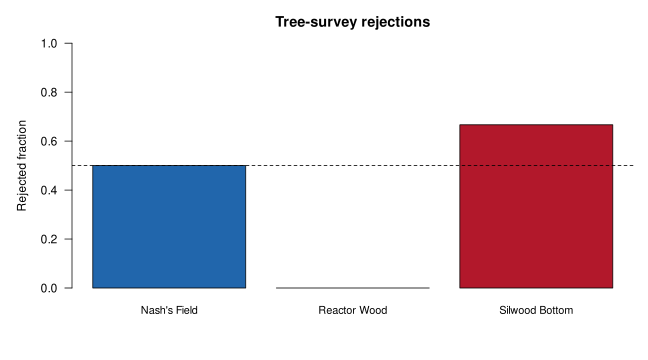

Actual command log saved; the notebook's independent hand checks also passed.


In [40]:
p1_execution_log = []
def portable_log_text(value):
    return str(value).replace(str(P1), "<PROJECT>").replace(PYTHON, "<PYTHON>")
def run_p1(command, ok=True):
    environment = os.environ.copy()
    environment["MQB_PYTHON"] = PYTHON
    result = subprocess.run([str(x) for x in command], cwd=P1, env=environment,
                            capture_output=True, text=True, timeout=90)
    p1_execution_log.append({"command": [portable_log_text(x) for x in command],
                             "returncode": result.returncode,
                             "stdout": portable_log_text(result.stdout), "stderr": portable_log_text(result.stderr)})
    if (result.returncode == 0) != ok:
        raise AssertionError(result.stdout + result.stderr)
    if result.stdout.strip():
        print(result.stdout.strip()[:2000])
    return result

run_p1([PYTHON, "code/test_workshop_pipeline.py"])
run_p1(["bash", "code/workshop_run_pipeline.sh", "tree",
        "data/workshop_tree_outcomes.csv", "results/workshop_demo"])
# These checks live in the notebook, outside the agent-editable project tests.
with (P1 / "results/workshop_demo/summary.csv").open(newline="") as stream:
    independently_checked = {row["location"]: row for row in csv.DictReader(stream)}
assert math.isclose(float(independently_checked["Silwood Bottom"]["rejection_fraction"]), 2/3)
assert independently_checked["Silwood Bottom"]["flagged"] == "true"
assert independently_checked["Nash's Field"]["flagged"] == "false"
assert independently_checked["Reactor Wood"]["top_reasons"] == ""
assert p1_protected == {name: hashlib.sha256((P1 / name).read_bytes()).hexdigest()
                         for name in p1_protected}
bad_csv = write_p1("results/workshop_mismatch.csv",
    (P1 / "results/workshop_demo/summary.csv").read_text().replace("rejection_fraction", "wrong_units", 1))
run_p1(["Rscript", "code/workshop_plot_results.R", bad_csv, "results/workshop_mismatch.svg", "tree"], ok=False)
assert not (P1 / "results/workshop_mismatch.svg").exists()
write_p1("replay/execution_log.json", json.dumps({
    "authoring_tool": "Codex coding assistant",
    "authoring_date": "2026-10-22",
    "record_type": "actual local command results for this AI-assisted chapter draft",
    "not_a_copilot_ui_recording": True,
    "machine_specific_paths_normalised": True,
    "exact_model_identifier": "not recorded",
    "commands": p1_execution_log,
}, indent=2) + "\n")
from IPython.display import SVG, display
display(SVG(filename=str(P1 / "results/workshop_demo/figure.svg")))
print("Actual command log saved; the notebook's independent hand checks also passed.")


Inspect the figure: Silwood should be above the dashed half-rejection line and coloured as flagged; Nash's Field is exactly on the line and is not flagged. The title and axes must say what was plotted, not merely “results”. Check the A/C transfer figures in the test-output directories too.

Now explain, without the assistant:

1. One interface decision that prevented a wrong result.
2. One agent change you accepted, revised or rejected, with the check supporting it.
3. Why a `SUCCESS` file, or an agent announcing “tests passed”, is not by itself scientific validation.

Keep the plan, reviewed diff, independent new test, execution log and run command. A lab mate should not need your current kernel, a chat transcript and a séance to reproduce the figure.


### Keep the evidence, not the entire conversation

Finish with three sentences: where assistance saved effort; which scientifically consequential error a check caught or would catch; and one rule you will use next time. Record the actual tool/date, contribution and independent check when acknowledgement is required.

The next cell checks that the source data stayed unchanged and saves the practice project in a new archive outside its folder. Copy that archive to a permanent location before clearing temporary files.

If you return to a task later, preserve your own implementation under a distinct filename and rerun its checks. The goal is not to remember every semicolon. It is to know what the program is claiming about the biology.


In [41]:
assert SOURCE_HASHES == {name: hashlib.sha256((WORKSPACE / "data" / name).read_bytes()).hexdigest()
                         for name in SOURCE_HASHES}
assert hashlib.sha256((WORKSPACE / "data/workshop_tree_outcomes.csv").read_bytes()).hexdigest() == tree_outcomes_hash
archive_base = WORKSPACE.parent / (WORKSPACE.name + "-saved")
saved_project = shutil.make_archive(str(archive_base), "zip", root_dir=WORKSPACE)
print("Supplied source inputs are unchanged.")
print("Saved practice project:", saved_project)
print("Contains scripts, fixtures, outputs and the P1 before/after files, diff and execution log.")


Supplied source inputs are unchanged.
Saved practice project: /tmp/mqb-ai-coding-cziyqc3b-saved.zip
Contains scripts, fixtures, outputs and the P1 before/after files, diff and execution log.


(ai-references)=
## 8. References

### Teaching, generation and reasoning

- Chen, M. et al. (2021). [Evaluating Large Language Models Trained on Code](https://arxiv.org/abs/2107.03374). An early empirical study of code generation and functional correctness.
- Krathwohl, D. R. (2002). [A Revision of Bloom's Taxonomy: An Overview](https://doi.org/10.1207/s15430421tip4104_2). *Theory Into Practice*, 41(4), 212–218.
- ICL Research Computing and Data Science: [Introduction to AI-Assisted Programming](https://github.com/ImperialCollegeLondon/RCDS-introduction-to-AI-assisted-programming) and the [course listing](https://www.imperial.ac.uk/early-career-researcher-institute/learning-and-development/courses-by-programme/research-computing-and-data-science/ai-assisted/). Its progression through generation, examining, editing and writing code informed this chapter's teaching design. The source course's materials carry a [CC BY-NC-SA 4.0 licence](https://github.com/ImperialCollegeLondon/RCDS-introduction-to-AI-assisted-programming/blob/main/Licence.md). This chapter uses newly written MQB explanations and practice candidates, not copied ICL passages or code; this credit does not change MQB's repository licence.
- MQB: [Python](python.ipynb), [R](r.ipynb), [Unix](unix.ipynb), [VS Code](../appendices/vscode.md) and [Copilot setup](../appendices/vscode-copilot.md). Practical cards link their source examples and distinguish original scaffolds from new candidates. The downloadable source-input pack includes MQB's MIT licence.
- MQB algorithms development: [draft chapter](https://github.com/MulQuaBio/MQB/blob/docs/algorithms-problem-solving-review/content/notebooks/algorithms.md), [draft lecture](https://github.com/MulQuaBio/MQB/blob/docs/algorithms-problem-solving-review/content/lectures/algorithms/algorithms.qmd) and [issue 220](https://github.com/MulQuaBio/MQB/issues/220). For assessment development, see [MQB AI Assessor](https://github.com/MulQuaBio/MQB_AI_Assessor).

### Interfaces, data use and controls

Data-use sources checked on **22 October 2026**; the mode, model and permissions guidance was checked on **23 October 2026**. Recheck the current source for your service, plan and workspace.

- Visual Studio Code: [Agent workflow overview](https://code.visualstudio.com/docs/agents/overview), [release notes](https://code.visualstudio.com/updates), [built-in agents](https://code.visualstudio.com/docs/agents/run/agent-harnesses#choose-a-built-in-agent), [Chat view controls](https://code.visualstudio.com/docs/agents/run/chat-view), [inline and Quick Chat](https://code.visualstudio.com/docs/chat/inline-chat), and the [legacy Edit-mode change](https://code.visualstudio.com/updates/v1_126#_edit-mode).
- Visual Studio Code: [model configuration](https://code.visualstudio.com/docs/agent-customization/language-models), [model concepts and task-based selection](https://code.visualstudio.com/docs/agents/concepts/language-models), and [approvals and permissions](https://code.visualstudio.com/docs/agents/run/approvals).
- GitHub: [current Copilot plan comparison](https://docs.github.com/en/copilot/get-started/plans) for account-dependent model access and allowances.
- GitHub: [Copilot on GitHub.com](https://docs.github.com/en/copilot/concepts/copilot-surfaces/copilot-on-github), [model hosting](https://docs.github.com/en/copilot/reference/ai-models/model-hosting), [individual Copilot policies and training control](https://docs.github.com/en/copilot/how-tos/manage-your-account/manage-policies), and [General Privacy Statement](https://docs.github.com/en/site-policy/privacy-policies/github-general-privacy-statement).
- OpenAI: [API data controls](https://developers.openai.com/api/docs/guides/your-data), [ChatGPT Work cloud security](https://learn.chatgpt.com/docs/enterprise/chatgpt-work-cloud-security), and the [browser guide's Data controls pointer](https://learn.chatgpt.com/docs/browser#privacy-and-browser-data). The last source identifies the settings location; it does not establish every personal ChatGPT training or retention default. Those defaults remain a source-verification item for this draft.

### Checking language behaviour

- Python: [mathematical functions](https://docs.python.org/3/library/math.html) for radians and `tan`; [profilers in Python 3.12](https://docs.python.org/3.12/library/profile.html) for the profiling interface used here. The versioned profiler page matches the chapter's `cProfile` examples.
- Check installed shell flags with `man grep`, `man find` and `man ls` where available. R3/U1 let you test the commands on practice files and compare their behaviour on your operating system.
